# Hipótese 5: O Tempo de Normalização das Portas E as Manutenções Corretivas Realizadas Tem Correlação?

## 1. Contexto e Fundamentação Teórica
As Portas de Plataforma (PSDs) são equipamentos eletromecânicos submetidos a ciclos contínuos de abertura e fechamento (ciclagens) para permitir o embarque e desembarque seguro de passageiros nas estações.

A hipótese operacional central estabelece que o tempo que ela demore para ser normalizadas são as que precisam ser consertadas ou dando problemas mais para frente. Isso nos trará dois dados importantes: tempos pequenos de normalização são exclusivamente portas que tiveram apenas obstrução e caso o tempo de normalização passe de X horas, deve ser consertada. 

---

## 2. Definindo a Questão Investigada
* **Portas e seu tempo de normalização**: O tempo para normalizar/fechar é um tempo em que a porta demora para voltar para seu funcionamento normal, mas há tempos bem grandes (chegando à quase 12h). A ideia é comprarar todas as portas que tiveram o tempo de normalização com os problemas, fazendo uma só planilha e ver se o tempo está relacionado à algum problema ou algo do tipo.

---

## Começando a tocar nas Hipóteses

### Passo 1. Entendimento das bases e definição da estrutura da análise

Inicialmente, foram identificadas e analisadas as principais bases utilizadas no notebook:

- **Alarmes PSD:** 150.003 registros;
- **SAP ZM01 — Corretiva Emergencial:** 10.647 registros;
- **SAP ZM02 — Corretiva Programada:** 1.163 registros.

### Estrutura das bases

A base de **Alarmes PSD** contém informações sobre a ocorrência e a normalização dos eventos do sistema PSD, incluindo os seguintes campos:

- `TAG`
- `Horário do Alarme`
- `Horário da Normalizacao`
- `Estação`
- `Porta`
- `Alarme`

As bases **SAP** contêm registros de manutenção, com informações como:

- `Local de Instalação`
- `Início da Avaria`
- `Fim da Avaria`
- `Sintoma`
- `Objeto`
- `Defeito`
- `Causa`

### Diferenças temporais entre as fontes

Nesta etapa, também foi identificado que as fontes possuem **significados temporais diferentes**.

Na base de **Alarmes PSD**, o tempo representa o intervalo entre:

> ocorrência do alarme → normalização do alarme

Já nas bases **SAP**, o tempo representa o intervalo entre:

> início da avaria → fim registrado da avaria

Essa diferença é importante para as análises posteriores, pois os intervalos temporais das duas fontes não representam necessariamente o mesmo fenômeno.

### Estratégia de cruzamento das bases

Como não existia um identificador direto ligando as bases, foi definido que o cruzamento posterior seria realizado por meio de uma **chave física comum**, formada por:

**Estação + Plataforma + Porta**

Para isso, essas informações precisariam ser extraídas e padronizadas a partir de:

- `TAG`, na base de Alarmes PSD;
- `Local de Instalação`, nas bases SAP.

### Preservação das bases originais

Também foi definido que as **bases originais seriam preservadas**, evitando a exclusão antecipada de registros.

Os filtros seriam aplicados apenas quando uma análise específica exigisse determinados campos, como:

- horário de início;
- horário de fim da avaria;
- localização completa;
- identificação da estação;
- identificação da plataforma;
- identificação da porta.

Essa abordagem permite manter o máximo possível de informação disponível durante as diferentes etapas da análise.

### Resultado da etapa

Ao final desta etapa, as três bases ainda permaneciam separadas:

1. **Alarmes PSD**
2. **SAP ZM01 — Corretiva Emergencial**
3. **SAP ZM02 — Corretiva Programada**

O objetivo deste primeiro passo foi compreender a estrutura das fontes, identificar quais informações poderiam ser relacionadas e definir a estratégia de tratamento e integração que seria aplicada nas etapas seguintes.


In [2]:
from pathlib import Path
import pandas as pd
import openpyxl

correcao_emergencial = pd.read_excel(
    "../../data/Ordens do SAP - Corretiva emergencial (ZM01).XLSX"
)

correcao_programada = pd.read_excel(
    "../../data/Ordens do SAP -Corretiva programada (ZM02).XLSX"
)

alarmes = pd.read_excel(
    "../../data/Alarmes do sistema de PSD.xlsx"
)

print("Emergencial:", correcao_emergencial.shape)
print("Programada:", correcao_programada.shape)
print("Alarmes:", alarmes.shape)

Emergencial: (10647, 28)
Programada: (1163, 28)
Alarmes: (150003, 7)


In [3]:
display(correcao_emergencial.head())
display(correcao_programada.head())
display(alarmes.head())

,Tipo de Nota,Nota,Ordem,Indisponível,Falha,IQM,Analisada,Comentários Classificação Engenharia,Perfil do catálogo,Descrição,...,Centro de Trabalho Responsável,Sintoma,Objeto,Defeito,Causa,Ação,Data Análise,Hora Análise,Encerram.por Data,Hora de Encerramento
0,Z1,14943931,53954586.0,X,X,NaN,NaN,MI/ NVT1 - AVARIADA,6PSD,PSD PL 01-02 Sem status para o CCO,...,SP04IBUT,LAÇO DE PDM ABERTO,NaN,NaN,NaN,NaN,2025-12-05,17:50:50,NaT,00:00:00
1,Z1,15133619,54145839.0,NaN,NaN,NaN,X,DU,6PSD,PSD - PDM's não abriram PLT02,...,SP04IBUT,TODAS AS PDM DA FACHADA NÃO ABREM,CABEAMENTO,CONTROLADOR PCC COMUNICACAO,ERRO DE COMUNICAÇÃO,RESETADO E TESTADO,2026-03-03,17:48:50,2026-02-27,14:26:36
2,Z1,13894133,52913343.0,NaN,NaN,NaN,X,CF/FALHA COMUNICAÇÃO,6PSD,PSD server s/ status das plataformas,...,SP04IBUT,PSD SERVER COM INDICAÇÃO DE FALHA NA PLA,RACK WCN,SENSOR DESTRAVADO AVARIADO,DESGASTE,RESETADO E TESTADO,NaT,00:00:00,2024-04-18,07:33:25
3,Z1,14713349,53724958.0,X,NaN,NaN,X,NC/ RESET,6PSD,BUT PLT 1 PORTAS NAO ABRIRAM,...,SP04IBUT,TODAS AS PDM DA FACHADA NÃO ABREM,CABO/CONECTORES,SWITCH TRAVADO,DESGASTE,RESETADO E TESTADO,2025-08-14,16:38:16,2025-07-08,04:40:58
4,Z1,14643768,53655728.0,X,NaN,NaN,X,NC/RESET,6PSD,PSD plt 1 - Falha geral de abertura,...,SP04IBUT,PDM NÃO ABRE,CABEAMENTO,BAIXA ISOLACAO,FALHA CBTC,RESETADO E TESTADO,2025-05-29,10:58:06,2025-05-28,14:37:13


,Tipo de Nota,Nota,Ordem,Indisponível,Falha,IQM,Analisada,Comentários Classificação Engenharia,Perfil do catálogo,Descrição,...,Centro de Trabalho Responsável,Sintoma,Objeto,Defeito,Causa,Ação,Data Análise,Hora Análise,Encerram.por Data,Hora de Encerramento
0,Z2,15069252,54081268.0,NaN,NaN,NaN,NaN,NaN,6PSD,Porta PCC-PSD a,...,SP04IBUT,PDM NÃO ABRE,"ESTRUTURA, ACABAMENTO, E ACESSÓRIOS DO P",PORTA DESAJUSTADA,FALTA FIXACAO,FIXADO,NaT,00:00:00,2026-01-25,16:50:18
1,Z2,14647619,53659484.0,NaN,NaN,NaN,NaN,NaN,6PSD,PDMs plat 1 e 2 com falha momentânea.,...,SP04IBUT,MAU CONTATO,SWITCK DE COMUNICAÇÃO,SEM CONEXAO ELETRICA,ERRO DE SOFTWARE,RESETADO E TESTADO,NaT,00:00:00,2025-06-01,04:36:44
2,Z2,14682623,53694340.0,NaN,NaN,NaN,NaN,NaN,6PSD,Rele painel SSE intermitente,...,SP04IBUT,FACHADA PSD SEM ALIMENTAÇÃO,DISPOSITIVO DE PROTECAO,CONVERSOR DE TENSAO AVARIADO,OPERACAO INDEVIDA,SUBSTITUIDO(A),NaT,00:00:00,2025-06-19,05:10:12
3,Z2,14864269,53874165.0,NaN,NaN,NaN,NaN,NaN,6PSD,Multimedidor SSE moldura solta,...,SP04IBUT,ESTRUTURA DANIFICADA,MULTIMEDIDOR,VIDRO QUEBRADO,DESGASTE,SUBSTITUIDO(A),NaT,00:00:00,2025-09-30,14:53:22
4,Z2,13390549,52423535.0,NaN,NaN,NaN,NaN,NaN,6PSD,Volume do P.A baixo.,...,SP04IBUT,SERVIDOR SEM COMUNICACAO,SWITCK DE COMUNICAÇÃO,BAIXA ISOLACAO,FALTA FIXACAO,APERTADO(A),NaT,00:00:00,2023-07-27,13:52:02


,TAG,Horário do Alarme,Estação,Porta,Alarme,Horário da Normalizacao,Tempo de Normalização
0,PSD_FAL_FAL2_PDM09_OBS,2026-05-12 08:16:52.657,FAL,9.0,OBS,2026-05-12 08:16:53.670,"0 dias, 00:00:01"
1,PSD_LUZ_LUZ1_PDM08_OBS,2026-05-12 08:15:09.913,LUZ,8.0,OBS,2026-05-12 08:15:10.917,"0 dias, 00:00:01"
2,PSD_FAL_FAL1_PDM15_OBS,2026-05-12 08:14:06.657,FAL,15.0,OBS,2026-05-12 08:14:07.670,"0 dias, 00:00:01"
3,PSD_LUZ_LUZ1_PDM19_OBS,2026-05-12 08:09:31.930,LUZ,19.0,OBS,2026-05-12 08:09:32.917,"0 dias, 00:00:01"
4,PSD_FRE_FRE1_PDM14_OBS,2026-05-12 08:05:05.830,FRE,14.0,OBS,2026-05-12 08:05:14.847,"0 dias, 00:00:09"


In [4]:
correcao_emergencial = correcao_emergencial[
    ["Local de Instalação", "Início avaria", "Hora início avaria", "Fim da avaria", "Hora do fim da avaria", "Sintoma", "Objeto", "Defeito", "Causa"]
]

correcao_programada = correcao_programada[
    ["Local de Instalação", "Início avaria", "Hora início avaria", "Fim da avaria", "Hora do fim da avaria", "Sintoma", "Objeto", "Defeito", "Causa"]
]

display(correcao_emergencial.head())
display(correcao_programada.head())
display(alarmes.head())

,Local de Instalação,Início avaria,Hora início avaria,Fim da avaria,Hora do fim da avaria,Sintoma,Objeto,Defeito,Causa
0,SP04-6-PSD-BUT,14/11/2025,06:35:28,NaN,00:00:00,LAÇO DE PDM ABERTO,NaN,NaN,NaN
1,SP04-6-PSD-BUT,27/02/2026,07:33:00,27/02/2026,12:00:00,TODAS AS PDM DA FACHADA NÃO ABREM,CABEAMENTO,CONTROLADOR PCC COMUNICACAO,ERRO DE COMUNICAÇÃO
2,SP04-6-PSD-BUT-P1S1,18/04/2024,06:00:00,18/04/2024,07:30:00,PSD SERVER COM INDICAÇÃO DE FALHA NA PLA,RACK WCN,SENSOR DESTRAVADO AVARIADO,DESGASTE
3,SP04-6-PSD-BUT-P1S1,07/07/2025,18:38:00,08/07/2025,03:00:00,TODAS AS PDM DA FACHADA NÃO ABREM,CABO/CONECTORES,SWITCH TRAVADO,DESGASTE
4,SP04-6-PSD-BUT-P1S1-PSSE1,28/05/2025,09:10:00,28/05/2025,10:00:00,PDM NÃO ABRE,CABEAMENTO,BAIXA ISOLACAO,FALHA CBTC


,Local de Instalação,Início avaria,Hora início avaria,Fim da avaria,Hora do fim da avaria,Sintoma,Objeto,Defeito,Causa
0,SP04-6-PSD-BUT,25/01/2026,08:20:00,25/01/2026,09:30:00,PDM NÃO ABRE,"ESTRUTURA, ACABAMENTO, E ACESSÓRIOS DO P",PORTA DESAJUSTADA,FALTA FIXACAO
1,SP04-6-PSD-BUT-P1S1,30/05/2025,09:30:00,01/06/2025,04:00:00,MAU CONTATO,SWITCK DE COMUNICAÇÃO,SEM CONEXAO ELETRICA,ERRO DE SOFTWARE
2,SP04-6-PSD-BUT-P2S1-PSSE2,19/06/2025,02:00:00,19/06/2025,04:30:00,FACHADA PSD SEM ALIMENTAÇÃO,DISPOSITIVO DE PROTECAO,CONVERSOR DE TENSAO AVARIADO,OPERACAO INDEVIDA
3,SP04-6-PSD-BUT-P2S1-PSSE2,30/09/2025,09:00:00,30/09/2025,12:00:00,ESTRUTURA DANIFICADA,MULTIMEDIDOR,VIDRO QUEBRADO,DESGASTE
4,SP04-6-PSD-BUT-PLT1,21/07/2023,14:00:00,27/07/2023,13:50:56,SERVIDOR SEM COMUNICACAO,SWITCK DE COMUNICAÇÃO,BAIXA ISOLACAO,FALTA FIXACAO


,TAG,Horário do Alarme,Estação,Porta,Alarme,Horário da Normalizacao,Tempo de Normalização
0,PSD_FAL_FAL2_PDM09_OBS,2026-05-12 08:16:52.657,FAL,9.0,OBS,2026-05-12 08:16:53.670,"0 dias, 00:00:01"
1,PSD_LUZ_LUZ1_PDM08_OBS,2026-05-12 08:15:09.913,LUZ,8.0,OBS,2026-05-12 08:15:10.917,"0 dias, 00:00:01"
2,PSD_FAL_FAL1_PDM15_OBS,2026-05-12 08:14:06.657,FAL,15.0,OBS,2026-05-12 08:14:07.670,"0 dias, 00:00:01"
3,PSD_LUZ_LUZ1_PDM19_OBS,2026-05-12 08:09:31.930,LUZ,19.0,OBS,2026-05-12 08:09:32.917,"0 dias, 00:00:01"
4,PSD_FRE_FRE1_PDM14_OBS,2026-05-12 08:05:05.830,FRE,14.0,OBS,2026-05-12 08:05:14.847,"0 dias, 00:00:09"


In [5]:
print("Alarmes:")
print(alarmes.isnull().sum())

print("\nCorretiva emergencial:")
print(correcao_emergencial.isnull().sum())

print("\nCorretiva programada:")
print(correcao_programada.isnull().sum())

Alarmes:
TAG                            1
Horário do Alarme          37252
Estação                        3
Porta                          3
Alarme                         3
Horário da Normalizacao        3
Tempo de Normalização          3
dtype: int64

Corretiva emergencial:
Local de Instalação         0
Início avaria               0
Hora início avaria          0
Fim da avaria             326
Hora do fim da avaria       0
Sintoma                     0
Objeto                    982
Defeito                   986
Causa                    1045
dtype: int64

Corretiva programada:
Local de Instalação       0
Início avaria             0
Hora início avaria        0
Fim da avaria            39
Hora do fim da avaria     0
Sintoma                   0
Objeto                   39
Defeito                  39
Causa                    42
dtype: int64


# Passo 2. Padronização da localização física dos alarmes

A segunda etapa foi dedicada à construção de uma **localização física padronizada** para cada alarme, com o objetivo de permitir comparações posteriores com os registros de manutenção do SAP.

## Construção das chaves de localização

Foram criadas três chaves principais:

- `estacao_key`
- `plataforma_key`
- `porta_key`

A estação foi padronizada a partir da coluna `Estação`, enquanto a porta foi convertida para um formato numérico consistente a partir da coluna `Porta`.

O principal desafio desta etapa foi a identificação da **plataforma**, pois essa informação não estava disponível diretamente em uma coluna específica da base.

## Primeiro padrão de TAG

Inicialmente, a plataforma foi extraída da coluna `TAG` utilizando o padrão mais comum encontrado nos alarmes.

Um exemplo desse formato é:

> `PSD_FAL_FAL2_PDM09_OBS`

Nesse padrão, a própria TAG contém informações que permitem identificar:

- estação;
- plataforma;
- porta;
- tipo de alarme.

Com essa primeira regra de extração, foi possível identificar a plataforma de **137.178 registros**.

## Segundo padrão de TAG

Após analisar os registros restantes, foi identificado um segundo formato de TAG.

Um exemplo é:

> `PSD_P_BUT1_MDU16_STS`

Nesse padrão:

- `BUT` representa a **estação**;
- `1` representa a **plataforma**;
- `MDU16` identifica a **porta**.

Foram encontrados **12.822 registros** seguindo esse segundo padrão.

## Validação do segundo padrão

Antes de utilizar as informações extraídas dessas TAGs, foi realizada uma validação comparando:

- a estação extraída da TAG com a coluna original `Estação`;
- a porta extraída da TAG com a coluna original `Porta`.

A concordância encontrada foi de:

- **100% para estação**;
- **100% para porta**.

Essa validação confirmou que a estrutura identificada no segundo padrão de TAG era consistente, permitindo utilizar a plataforma extraída com segurança.

## Cobertura da localização física

Após considerar os dois padrões de TAG, foi possível construir a localização física para praticamente toda a base de alarmes.

A situação final ficou da seguinte forma:

- **150.003 alarmes** no total;
- **150.000 registros** com estação, plataforma e porta identificadas;
- apenas **3 registros** permaneceram sem localização física utilizável.

Esses três registros possuíam campos ausentes e não apresentavam informação suficiente para reconstruir sua localização de forma segura.

## Chave física final

Ao final desta etapa, praticamente toda a base de Alarmes PSD passou a possuir uma chave física formada por:

> **Estação + Plataforma + Porta**

Essa chave seria utilizada posteriormente para relacionar os alarmes com os registros de manutenção presentes nas bases SAP.

## Conclusão

A padronização da localização permitiu transformar diferentes formatos de TAG em uma estrutura física comum e consistente.

Com **150.000 dos 150.003 registros** contendo estação, plataforma e porta identificadas, a base de alarmes passou a estar preparada para o cruzamento com as informações de manutenção do SAP nas etapas seguintes.

In [6]:
import numpy as np
alarmes_trat = alarmes.copy()

# Estação
alarmes_trat["estacao_key"] = (
    alarmes_trat["Estação"]
    .astype("string")
    .str.strip()
    .str.upper()
)

# Porta
alarmes_trat["porta_key"] = pd.to_numeric(
    alarmes_trat["Porta"],
    errors="coerce"
).astype("Int64")

# Extrair plataforma da TAG
# Exemplo: PSD_FAL_FAL2_PDM09_OBS
plataforma = alarmes_trat["TAG"].astype(str).str.extract(
    r"(?:^|_)([A-Z]{3})([12])_PDM(\d{2})(?:_|$)"
)

alarmes_trat["plataforma_key"] = pd.to_numeric(
    plataforma[1],
    errors="coerce"
).astype("Int64")

In [7]:
alarmes_trat["inicio_alarme"] = pd.to_datetime(
    alarmes_trat["Horário do Alarme"],
    errors="coerce"
)

alarmes_trat["fim_alarme"] = pd.to_datetime(
    alarmes_trat["Horário da Normalizacao"],
    errors="coerce"
)

In [8]:
alarmes_trat["tempo_normalizacao"] = (
    alarmes_trat["fim_alarme"]
    - alarmes_trat["inicio_alarme"]
)

alarmes_trat["tempo_normalizacao_min"] = (
    alarmes_trat["tempo_normalizacao"]
    .dt.total_seconds() / 60
)

In [9]:
display(
    alarmes_trat[
        [
            "TAG",
            "estacao_key",
            "plataforma_key",
            "porta_key",
            "inicio_alarme",
            "fim_alarme",
            "tempo_normalizacao_min"
        ]
    ].head(10)
)

,TAG,estacao_key,plataforma_key,porta_key,inicio_alarme,fim_alarme,tempo_normalizacao_min
0,PSD_FAL_FAL2_PDM09_OBS,FAL,2,9,2026-05-12 08:16:52.657,2026-05-12 08:16:53.670,0.016883
1,PSD_LUZ_LUZ1_PDM08_OBS,LUZ,1,8,2026-05-12 08:15:09.913,2026-05-12 08:15:10.917,0.016733
2,PSD_FAL_FAL1_PDM15_OBS,FAL,1,15,2026-05-12 08:14:06.657,2026-05-12 08:14:07.670,0.016883
3,PSD_LUZ_LUZ1_PDM19_OBS,LUZ,1,19,2026-05-12 08:09:31.930,2026-05-12 08:09:32.917,0.016450
4,PSD_FRE_FRE1_PDM14_OBS,FRE,1,14,2026-05-12 08:05:05.830,2026-05-12 08:05:14.847,0.150283
5,PSD_FRE_FRE1_PDM14_OBS,FRE,1,14,2026-05-12 08:05:02.847,2026-05-12 08:05:03.847,0.016667
6,PSD_LUZ_LUZ1_PDM15_OBS,LUZ,1,15,2026-05-12 07:52:33.930,2026-05-12 07:52:34.930,0.016667
7,PSD_HIG_HIG1_PDM16_OBS,HIG,1,16,2026-05-12 07:52:23.820,2026-05-12 07:52:24.820,0.016667
8,PSD_FAL_FAL1_PDM14_OBS,FAL,1,14,2026-05-12 07:50:21.703,2026-05-12 07:50:22.670,0.016117
9,PSD_LUZ_LUZ1_PDM08_OBS,LUZ,1,8,2026-05-12 07:33:46.900,2026-05-12 07:33:47.900,0.016667


In [10]:
programada_trat = correcao_programada.copy()

In [11]:
# Extrair estação do Local de Instalação
programada_trat["estacao_key"] = (
    programada_trat["Local de Instalação"]
    .astype(str)
    .str.extract(r"PSD-([A-Z]{3})", expand=False)
)

# Extrair plataforma
programada_trat["plataforma_key"] = pd.to_numeric(
    programada_trat["Local de Instalação"]
    .astype(str)
    .str.extract(r"PLT([12])", expand=False),
    errors="coerce"
).astype("Int64")

# Extrair porta
programada_trat["porta_key"] = pd.to_numeric(
    programada_trat["Local de Instalação"]
    .astype(str)
    .str.extract(r"PP(\d{2})PDM", expand=False),
    errors="coerce"
).astype("Int64")

In [12]:
data_inicio = pd.to_datetime(
    programada_trat["Início avaria"],
    dayfirst=True,
    errors="coerce"
)

hora_inicio = pd.to_timedelta(
    programada_trat["Hora início avaria"].astype(str),
    errors="coerce"
)

programada_trat["inicio_avaria_dt"] = (
    data_inicio.dt.normalize()
    + hora_inicio
)

In [13]:
data_fim = pd.to_datetime(
    programada_trat["Fim da avaria"],
    dayfirst=True,
    errors="coerce"
)

hora_fim = pd.to_timedelta(
    programada_trat["Hora do fim da avaria"].astype(str),
    errors="coerce"
)

programada_trat["fim_avaria_dt"] = (
    data_fim.dt.normalize()
    + hora_fim
)

In [14]:
programada_trat["duracao_avaria"] = (
    programada_trat["fim_avaria_dt"]
    - programada_trat["inicio_avaria_dt"]
)

programada_trat["duracao_avaria_min"] = (
    programada_trat["duracao_avaria"]
    .dt.total_seconds() / 60
)

In [15]:
display(
    programada_trat[
        [
            "Local de Instalação",
            "estacao_key",
            "plataforma_key",
            "porta_key",
            "inicio_avaria_dt",
            "fim_avaria_dt",
            "duracao_avaria_min",
            "Sintoma",
            "Objeto",
            "Defeito",
            "Causa"
        ]
    ].head(10)
)

,Local de Instalação,estacao_key,plataforma_key,porta_key,inicio_avaria_dt,fim_avaria_dt,duracao_avaria_min,Sintoma,Objeto,Defeito,Causa
0,SP04-6-PSD-BUT,BUT,<NA>,<NA>,2026-01-25 08:20:00,2026-01-25 09:30:00,70.000000,PDM NÃO ABRE,"ESTRUTURA, ACABAMENTO, E ACESSÓRIOS DO P",PORTA DESAJUSTADA,FALTA FIXACAO
1,SP04-6-PSD-BUT-P1S1,BUT,<NA>,<NA>,2025-05-30 09:30:00,2025-06-01 04:00:00,2550.000000,MAU CONTATO,SWITCK DE COMUNICAÇÃO,SEM CONEXAO ELETRICA,ERRO DE SOFTWARE
2,SP04-6-PSD-BUT-P2S1-PSSE2,BUT,<NA>,<NA>,2025-06-19 02:00:00,2025-06-19 04:30:00,150.000000,FACHADA PSD SEM ALIMENTAÇÃO,DISPOSITIVO DE PROTECAO,CONVERSOR DE TENSAO AVARIADO,OPERACAO INDEVIDA
3,SP04-6-PSD-BUT-P2S1-PSSE2,BUT,<NA>,<NA>,2025-09-30 09:00:00,2025-09-30 12:00:00,180.000000,ESTRUTURA DANIFICADA,MULTIMEDIDOR,VIDRO QUEBRADO,DESGASTE
4,SP04-6-PSD-BUT-PLT1,BUT,1,<NA>,2023-07-21 14:00:00,2023-07-27 13:50:56,8630.933333,SERVIDOR SEM COMUNICACAO,SWITCK DE COMUNICAÇÃO,BAIXA ISOLACAO,FALTA FIXACAO
5,SP04-6-PSD-BUT-PLT1,BUT,1,<NA>,2024-04-25 08:00:00,2024-04-25 15:30:00,450.000000,PDM NÃO FECHOU,ESTRUTURA E ACABAMENTOS PDM,ATUADOR DA TRAVA DE PDM DESAJUSTADO,ERRO DE COMUNICAÇÃO
6,SP04-6-PSD-BUT-PLT1-PFP1,BUT,1,<NA>,2023-04-30 17:40:50,2023-05-01 04:06:00,625.166667,ESTRUTURA DANIFICADA,PORTA FINAL PLATAF PFP,IHM TRAVADA,VANDALISMO
7,SP04-6-PSD-BUT-PLT1-PP05PDM,BUT,1,5,2025-02-20 04:00:33,2025-02-24 15:20:00,6439.450000,LAMPADA(S) NAO ACENDE(M),SPEAKER PDM,MCP TRAVADO,OPERACAO INDEVIDA
8,SP04-6-PSD-BUT-PLT1-PP06PSE,BUT,1,<NA>,2024-12-04 03:13:00,2025-08-02 01:30:00,346937.000000,PDM PESADA,LINGUETA DA TRAVA ESQUERDA PSE PSD,PORTA DESAJUSTADA,VIBRACAO
9,SP04-6-PSD-BUT-PLT1-PP10PDM,BUT,1,10,2023-12-09 15:00:00,2024-01-29 11:00:00,73200.000000,PORTA COM RUÍDO ANORMAL,ALTO-FALANTE (SPEAKER),MCP AVARIADO,ERRO DE COMUNICAÇÃO


In [16]:
emergencial_trat = correcao_emergencial.copy()

local = emergencial_trat["Local de Instalação"].astype(str)

In [17]:
emergencial_trat["estacao_key"] = local.str.extract(
    r"PSD-([A-Z]{3})",
    expand=False
)

In [18]:
emergencial_trat["plataforma_key"] = pd.to_numeric(
    local.str.extract(
        r"PLT([12])",
        expand=False
    ),
    errors="coerce"
).astype("Int64")

In [19]:
emergencial_trat["porta_key"] = pd.to_numeric(
    local.str.extract(
        r"PP(\d{2})PDM",
        expand=False
    ),
    errors="coerce"
).astype("Int64")

In [20]:
data_inicio = pd.to_datetime(
    emergencial_trat["Início avaria"],
    dayfirst=True,
    errors="coerce"
)

hora_inicio = pd.to_timedelta(
    emergencial_trat["Hora início avaria"].astype(str),
    errors="coerce"
)

emergencial_trat["inicio_avaria_dt"] = (
    data_inicio.dt.normalize()
    + hora_inicio
)

In [21]:
data_fim = pd.to_datetime(
    emergencial_trat["Fim da avaria"],
    dayfirst=True,
    errors="coerce"
)

hora_fim = pd.to_timedelta(
    emergencial_trat["Hora do fim da avaria"].astype(str),
    errors="coerce"
)

emergencial_trat["fim_avaria_dt"] = (
    data_fim.dt.normalize()
    + hora_fim
)

In [22]:
emergencial_trat["duracao_avaria"] = (
    emergencial_trat["fim_avaria_dt"]
    - emergencial_trat["inicio_avaria_dt"]
)

emergencial_trat["duracao_avaria_min"] = (
    emergencial_trat["duracao_avaria"]
    .dt.total_seconds() / 60
)

In [23]:
display(
    emergencial_trat[
        [
            "Local de Instalação",
            "estacao_key",
            "plataforma_key",
            "porta_key",
            "inicio_avaria_dt",
            "fim_avaria_dt",
            "duracao_avaria_min"
        ]
    ].head(10)
)

,Local de Instalação,estacao_key,plataforma_key,porta_key,inicio_avaria_dt,fim_avaria_dt,duracao_avaria_min
0,SP04-6-PSD-BUT,BUT,<NA>,<NA>,2025-11-14 06:35:28,NaT,NaN
1,SP04-6-PSD-BUT,BUT,<NA>,<NA>,2026-02-27 07:33:00,2026-02-27 12:00:00,267.000000
2,SP04-6-PSD-BUT-P1S1,BUT,<NA>,<NA>,2024-04-18 06:00:00,2024-04-18 07:30:00,90.000000
3,SP04-6-PSD-BUT-P1S1,BUT,<NA>,<NA>,2025-07-07 18:38:00,2025-07-08 03:00:00,502.000000
4,SP04-6-PSD-BUT-P1S1-PSSE1,BUT,<NA>,<NA>,2025-05-28 09:10:00,2025-05-28 10:00:00,50.000000
5,SP04-6-PSD-BUT-P1S1-PSSE1,BUT,<NA>,<NA>,2025-06-18 17:00:38,2025-06-19 04:00:00,659.366667
6,SP04-6-PSD-BUT-P2S1,BUT,<NA>,<NA>,2025-11-24 16:20:15,2025-11-24 17:30:00,69.750000
7,SP04-6-PSD-BUT-P2S1-PSSE2,BUT,<NA>,<NA>,2025-07-18 07:33:00,2025-07-19 05:18:29,1305.483333
8,SP04-6-PSD-BUT-PLT1,BUT,1,<NA>,2023-04-23 19:15:00,2023-04-23 20:20:00,65.000000
9,SP04-6-PSD-BUT-PLT1,BUT,1,<NA>,2023-09-06 16:16:00,2023-09-06 16:56:00,40.000000


In [24]:
# Extrair informações escondidas na TAG

alarmes_trat["estacao_tag"] = alarmes_trat["TAG"].str.extract(
    r"^PSD_([A-Z]{3})_",
    expand=False
)

alarmes_trat["plataforma_tag"] = pd.to_numeric(
    alarmes_trat["TAG"].str.extract(
        r"_[A-Z]{3}([12])_PDM",
        expand=False
    ),
    errors="coerce"
).astype("Int64")

alarmes_trat["porta_tag"] = pd.to_numeric(
    alarmes_trat["TAG"].str.extract(
        r"PDM(\d{2})",
        expand=False
    ),
    errors="coerce"
).astype("Int64")

alarmes_trat["alarme_tag"] = alarmes_trat["TAG"].str.extract(
    r"_([^_]+)$",
    expand=False
)

In [25]:
alarmes_trat["Estação"] = alarmes_trat["Estação"].fillna(
    alarmes_trat["estacao_tag"]
)

alarmes_trat["Porta"] = alarmes_trat["Porta"].fillna(
    alarmes_trat["porta_tag"]
)

alarmes_trat["Alarme"] = alarmes_trat["Alarme"].fillna(
    alarmes_trat["alarme_tag"]
)

In [26]:
alarmes_trat["Plataforma"] = alarmes_trat["plataforma_tag"]

In [27]:
alarmes_trat["inicio_alarme"] = pd.to_datetime(
    alarmes_trat["Horário do Alarme"],
    errors="coerce"
)

alarmes_trat["fim_alarme"] = pd.to_datetime(
    alarmes_trat["Horário da Normalizacao"],
    errors="coerce"
)

alarmes_trat["tempo_normalizacao_calc"] = (
    alarmes_trat["fim_alarme"]
    - alarmes_trat["inicio_alarme"]
)

alarmes_trat["tempo_normalizacao_min"] = (
    alarmes_trat["tempo_normalizacao_calc"]
    .dt.total_seconds() / 60
)

In [28]:
emergencial_trat["estacao_key"] = (
    emergencial_trat["Local de Instalação"]
    .str.extract(r"PSD-([A-Z]{3})", expand=False)
)

emergencial_trat["plataforma_key"] = pd.to_numeric(
    emergencial_trat["Local de Instalação"]
    .str.extract(r"PLT([12])", expand=False),
    errors="coerce"
).astype("Int64")

emergencial_trat["porta_key"] = pd.to_numeric(
    emergencial_trat["Local de Instalação"]
    .str.extract(r"PP(\d{2})PDM", expand=False),
    errors="coerce"
).astype("Int64")

In [29]:
programada_trat["estacao_key"] = (
    programada_trat["Local de Instalação"]
    .str.extract(r"PSD-([A-Z]{3})", expand=False)
)

programada_trat["plataforma_key"] = pd.to_numeric(
    programada_trat["Local de Instalação"]
    .str.extract(r"PLT([12])", expand=False),
    errors="coerce"
).astype("Int64")

programada_trat["porta_key"] = pd.to_numeric(
    programada_trat["Local de Instalação"]
    .str.extract(r"PP(\d{2})PDM", expand=False),
    errors="coerce"
).astype("Int64")

In [30]:
print(emergencial_trat.columns.tolist())

['Local de Instalação', 'Início avaria', 'Hora início avaria', 'Fim da avaria', 'Hora do fim da avaria', 'Sintoma', 'Objeto', 'Defeito', 'Causa', 'estacao_key', 'plataforma_key', 'porta_key', 'inicio_avaria_dt', 'fim_avaria_dt', 'duracao_avaria', 'duracao_avaria_min']


In [31]:
print(programada_trat.columns.tolist())

['Local de Instalação', 'Início avaria', 'Hora início avaria', 'Fim da avaria', 'Hora do fim da avaria', 'Sintoma', 'Objeto', 'Defeito', 'Causa', 'estacao_key', 'plataforma_key', 'porta_key', 'inicio_avaria_dt', 'fim_avaria_dt', 'duracao_avaria', 'duracao_avaria_min']


# Passo 3. Tratamento temporal da base de alarmes PSD

A terceira etapa foi dedicada ao tratamento das informações de tempo da base de **Alarmes PSD**, mantendo os **150.003 registros originais** e criando uma versão tratada para as análises.

## Análise das variáveis temporais

Foram analisadas principalmente as seguintes colunas:

- `Horário do Alarme`
- `Horário da Normalizacao`
- `Tempo de Normalização`

Os campos `Horário do Alarme` e `Horário da Normalizacao` já estavam armazenados em formato de **data e hora**, enquanto `Tempo de Normalização` estava armazenado como **texto**.

## Validação do tempo de normalização

Para verificar se a duração informada originalmente na planilha era confiável, a coluna textual `Tempo de Normalização` foi convertida para um formato temporal.

Em seguida, esse valor foi comparado com a duração calculada diretamente pela diferença entre:

> `Horário da Normalizacao` - `Horário do Alarme`

Essa validação foi possível em **112.751 registros**.

Aproximadamente **99,52% dos casos apresentaram uma diferença de no máximo 1 segundo** entre:

- o tempo informado originalmente na planilha;
- o tempo calculado a partir dos horários.

Esse resultado indicou uma **alta consistência** entre as duas formas de representar a duração dos alarmes.

## Definição da referência temporal

A partir dessa validação, optou-se por utilizar a diferença entre os **timestamps** como referência para as análises posteriores.

Foram criadas variáveis representando o tempo de normalização em:

- **segundos**;
- **minutos**.

Dessa forma, a duração utilizada nas análises passou a ser calculada diretamente a partir dos horários registrados.

## Registros sem horário do alarme

Também foi identificado que **37.252 registros não possuíam `Horário do Alarme`**.

Foi testada a possibilidade de reconstruir esse horário utilizando a relação:

> `Horário da Normalizacao` - `Tempo de Normalização`

Entretanto, os mesmos registros apresentavam valores **inválidos ou ausentes** na coluna textual `Tempo de Normalização`.

Portanto, não existia informação suficiente para recuperar esses horários de forma segura, sem introduzir estimativas ou valores potencialmente incorretos na base.

## Resultado da etapa

Ao final desta etapa, a situação da base de Alarmes PSD ficou da seguinte forma:

- **150.003 registros** preservados na base original;
- **112.751 registros** com tempo de normalização calculável;
- **37.252 registros** sem informação suficiente para calcular a duração do alarme.

Os registros sem duração calculável foram mantidos na base, mas não poderiam ser utilizados em análises que dependessem diretamente do tempo de normalização.

## Conclusão

A principal conclusão desta etapa foi que o **tempo de normalização calculado a partir dos horários é confiável**.

A elevada concordância entre a duração originalmente informada e a duração calculada pelos timestamps permite utilizar essa variável temporal com segurança nas etapas seguintes da análise.

In [32]:
fim_nulo_emergencial = (
    emergencial_trat["Fim da avaria"].isna()
    & emergencial_trat["Início avaria"].notna()
    & emergencial_trat["Hora início avaria"].notna()
    & emergencial_trat["Hora do fim da avaria"].notna()
)

print("Possíveis datas de fim recuperáveis:", fim_nulo_emergencial.sum())

Possíveis datas de fim recuperáveis: 326


In [33]:
data_inicio = pd.to_datetime(
    emergencial_trat["Início avaria"],
    dayfirst=True,
    errors="coerce"
)

hora_inicio = pd.to_timedelta(
    emergencial_trat["Hora início avaria"].astype(str),
    errors="coerce"
)

hora_fim = pd.to_timedelta(
    emergencial_trat["Hora do fim da avaria"].astype(str),
    errors="coerce"
)

In [34]:
data_fim_estimado = data_inicio.dt.normalize().copy()

# Se o horário final for menor que o inicial,
# significa que provavelmente virou o dia
virou_dia = hora_fim < hora_inicio

data_fim_estimado.loc[virou_dia] = (
    data_fim_estimado.loc[virou_dia]
    + pd.Timedelta(days=1)
)

In [35]:
# Datas e horários convertidos
data_inicio = pd.to_datetime(
    emergencial_trat["Início avaria"],
    dayfirst=True,
    errors="coerce"
)

hora_inicio = pd.to_timedelta(
    emergencial_trat["Hora início avaria"].astype(str),
    errors="coerce"
)

data_fim = pd.to_datetime(
    emergencial_trat["Fim da avaria"],
    dayfirst=True,
    errors="coerce"
)

hora_fim = pd.to_timedelta(
    emergencial_trat["Hora do fim da avaria"].astype(str),
    errors="coerce"
)

# Datetime de início
emergencial_trat["inicio_avaria_dt"] = (
    data_inicio.dt.normalize() + hora_inicio
)

# Datetime de fim quando a data original existe
emergencial_trat["fim_avaria_dt"] = (
    data_fim.dt.normalize() + hora_fim
)

In [36]:
fim_nulo_emergencial = (
    data_fim.isna()
    & data_inicio.notna()
    & hora_inicio.notna()
    & hora_fim.notna()
)

print("Possíveis casos para imputação:", fim_nulo_emergencial.sum())

Possíveis casos para imputação: 326


# Passo 4. Tratamento temporal das bases de manutenção do SAP

A quarta etapa foi dedicada ao tratamento das informações de tempo das bases de manutenção **ZM01** e **ZM02**.

## Construção dos campos de data e hora

Nas bases SAP, as informações de data e horário estavam armazenadas em colunas separadas.

Para cada registro, foram combinados:

- `Início avaria` com `Hora início avaria`;
- `Fim da avaria` com `Hora do fim da avaria`.

A partir dessas combinações, foram criadas as variáveis:

- `inicio_avaria_dt`
- `fim_avaria_dt`

Essas novas colunas passaram a representar o início e o fim da avaria em um único campo de data e hora.

## Cálculo da duração da avaria

Com os campos temporais padronizados, foi calculada a duração de cada avaria.

Foram criadas duas variáveis:

- `duracao_avaria`, representando a duração em formato temporal;
- `duracao_avaria_min`, representando a duração em minutos.

O cálculo foi realizado a partir da diferença entre:

> `fim_avaria_dt` - `inicio_avaria_dt`

## Tratamento da base ZM01

A base **ZM01**, referente às manutenções corretivas emergenciais, possuía **10.647 registros**.

Todos os registros apresentavam um início de avaria válido.

Em relação ao encerramento:

- **10.321 registros** possuíam fim de avaria válido e duração calculável;
- **326 registros** não possuíam informação suficiente para determinar o encerramento da avaria.

Esses registros foram mantidos na base, porém não poderiam ser utilizados em análises que dependessem da duração completa da manutenção.

## Tratamento da base ZM02

A base **ZM02**, referente às manutenções corretivas programadas, possuía **1.163 registros**.

Assim como na ZM01, todos os registros apresentavam um início de avaria válido.

Em relação ao encerramento:

- **1.124 registros** possuíam fim de avaria válido e duração calculável;
- **39 registros** não possuíam encerramento válido.

## Tratamento dos horários `00:00:00`

Durante o tratamento, foram encontrados registros em que `Fim da avaria` estava ausente, enquanto `Hora do fim da avaria` aparecia como:

> `00:00:00`

Inicialmente, foi considerada a possibilidade de interpretar esses casos como encerramentos ocorridos à meia-noite.

Entretanto, essa abordagem foi descartada, pois a ausência da data de término impedia determinar com segurança **em qual dia** a avaria havia sido encerrada.

Dessa forma, esses registros passaram a ser tratados como casos de:

> **fim de avaria desconhecido**

Essa decisão evitou a criação de datas de encerramento artificiais ou potencialmente incorretas.

## Preservação dos registros sem duração

Em uma etapa inicial da análise, alguns registros sem duração calculável chegaram a ser removidos para análises específicas.

Posteriormente, decidiu-se preservar novamente as bases completas.

Isso ocorreu porque uma manutenção sem horário de encerramento ainda pode conter informações relevantes para outras análises, como:

- início da avaria;
- localização;
- defeito;
- causa;
- sintoma;
- objeto da manutenção.

Portanto, a ausência de duração passou a ser tratada como uma **limitação específica para análises temporais**, e não como um critério automático de exclusão do registro.

## Resultado da etapa

Ao final desta etapa, as bases SAP ficaram com suas informações temporais padronizadas.

A situação final foi:

- **ZM01:** 10.647 registros, sendo **10.321 com duração calculável**;
- **ZM02:** 1.163 registros, sendo **1.124 com duração calculável**;
- **11.810 registros de manutenção** no total.

Os registros sem duração calculável foram mantidos nas respectivas bases para que suas demais informações continuassem disponíveis nas análises posteriores.

## Conclusão

A principal conclusão desta etapa foi que as informações temporais das bases SAP puderam ser padronizadas por meio da combinação das colunas de data e horário.

Assim como na base de alarmes, a ausência de duração passou a ser tratada como uma restrição apenas para análises que dependessem do intervalo completo da ocorrência, preservando os registros para os demais tipos de investigação.

In [37]:
fim_estimado = (
    data_inicio.dt.normalize()
    + hora_fim
)

# Se o horário final for menor que o horário inicial,
# assumimos que terminou no dia seguinte
virou_dia = (
    fim_nulo_emergencial
    & (hora_fim < hora_inicio)
)

fim_estimado.loc[virou_dia] = (
    fim_estimado.loc[virou_dia]
    + pd.Timedelta(days=1)
)

In [38]:
emergencial_trat["fim_avaria_imputado"] = False

emergencial_trat.loc[
    fim_nulo_emergencial,
    "fim_avaria_dt"
] = fim_estimado.loc[fim_nulo_emergencial]

emergencial_trat.loc[
    fim_nulo_emergencial,
    "fim_avaria_imputado"
] = True

In [39]:
display(
    emergencial_trat[
        emergencial_trat["fim_avaria_imputado"]
    ][
        [
            "Início avaria",
            "Hora início avaria",
            "Fim da avaria",
            "Hora do fim da avaria",
            "inicio_avaria_dt",
            "fim_avaria_dt",
            "duracao_avaria_min"
        ]
    ].head(20)
)

,Início avaria,Hora início avaria,Fim da avaria,Hora do fim da avaria,inicio_avaria_dt,fim_avaria_dt,duracao_avaria_min
0,14/11/2025,06:35:28,NaN,00:00:00,2025-11-14 06:35:28,2025-11-15,NaN
19,16/09/2025,18:44:00,NaN,00:00:00,2025-09-16 18:44:00,2025-09-17,NaN
49,14/10/2025,20:40:00,NaN,00:00:00,2025-10-14 20:40:00,2025-10-15,NaN
50,14/10/2025,23:05:00,NaN,00:00:00,2025-10-14 23:05:00,2025-10-15,NaN
67,08/02/2024,16:42:00,NaN,00:00:00,2024-02-08 16:42:00,2024-02-09,NaN
255,08/07/2024,15:54:00,NaN,00:00:00,2024-07-08 15:54:00,2024-07-09,NaN
270,08/08/2023,05:06:00,NaN,00:00:00,2023-08-08 05:06:00,2023-08-09,NaN
414,09/11/2024,06:36:00,NaN,00:00:00,2024-11-09 06:36:00,2024-11-10,NaN
696,03/03/2026,02:40:00,NaN,00:00:00,2026-03-03 02:40:00,2026-03-04,NaN
806,12/03/2024,19:13:00,NaN,00:00:00,2024-03-12 19:13:00,2024-03-13,NaN


In [40]:
mascara_fim_invalido = (
    emergencial_trat["Fim da avaria"].isna()
    & (
        pd.to_timedelta(
            emergencial_trat["Hora do fim da avaria"].astype(str),
            errors="coerce"
        ) == pd.Timedelta(0)
    )
)

print("Registros com fim inválido:", mascara_fim_invalido.sum())

Registros com fim inválido: 326


In [41]:
emergencial_trat.loc[
    mascara_fim_invalido,
    "fim_avaria_dt"
] = pd.NaT

In [42]:
emergencial_trat["duracao_avaria"] = (
    emergencial_trat["fim_avaria_dt"]
    - emergencial_trat["inicio_avaria_dt"]
)

emergencial_trat["duracao_avaria_min"] = (
    emergencial_trat["duracao_avaria"]
    .dt.total_seconds() / 60
)

In [43]:
print("Antes:", emergencial_trat.shape)

print(
    "Linhas com duração NaN:",
    emergencial_trat["duracao_avaria_min"].isna().sum()
)

Antes: (10647, 17)
Linhas com duração NaN: 326


In [44]:
emergencial_trat = emergencial_trat.dropna(
    subset=["duracao_avaria_min"]
)

In [45]:
print("Depois:", emergencial_trat.shape)
print(
    emergencial_trat["duracao_avaria_min"].isna().sum()
)

Depois: (10321, 17)
0


In [46]:
programada_trat = programada_trat.dropna(
    subset=["duracao_avaria_min"]
)

In [47]:
print(alarmes_trat[
    [
        "Horário do Alarme",
        "Horário da Normalizacao",
        "Tempo de Normalização"
    ]
].dtypes)

display(
    alarmes_trat[
        [
            "Horário do Alarme",
            "Horário da Normalizacao",
            "Tempo de Normalização"
        ]
    ].head(20)
)

print("\nValores nulos:")
print(
    alarmes_trat[
        [
            "Horário do Alarme",
            "Horário da Normalizacao",
            "Tempo de Normalização"
        ]
    ].isna().sum()
)

Horário do Alarme          datetime64[us]
Horário da Normalizacao    datetime64[us]
Tempo de Normalização                 str
dtype: object


,Horário do Alarme,Horário da Normalizacao,Tempo de Normalização
0,2026-05-12 08:16:52.657,2026-05-12 08:16:53.670,"0 dias, 00:00:01"
1,2026-05-12 08:15:09.913,2026-05-12 08:15:10.917,"0 dias, 00:00:01"
2,2026-05-12 08:14:06.657,2026-05-12 08:14:07.670,"0 dias, 00:00:01"
3,2026-05-12 08:09:31.930,2026-05-12 08:09:32.917,"0 dias, 00:00:01"
4,2026-05-12 08:05:05.830,2026-05-12 08:05:14.847,"0 dias, 00:00:09"
5,2026-05-12 08:05:02.847,2026-05-12 08:05:03.847,"0 dias, 00:00:01"
6,2026-05-12 07:52:33.930,2026-05-12 07:52:34.930,"0 dias, 00:00:01"
7,2026-05-12 07:52:23.820,2026-05-12 07:52:24.820,"0 dias, 00:00:01"
8,2026-05-12 07:50:21.703,2026-05-12 07:50:22.670,"0 dias, 00:00:01"
9,2026-05-12 07:33:46.900,2026-05-12 07:33:47.900,"0 dias, 00:00:01"



Valores nulos:
Horário do Alarme          37252
Horário da Normalizacao        3
Tempo de Normalização          3
dtype: int64


In [48]:
tempo_original = pd.to_timedelta(
    alarmes_trat["Tempo de Normalização"]
    .str.replace(
        r"(\d+)\s+dias?,\s*",
        r"\1 days ",
        regex=True
    ),
    errors="coerce"
)

tempo_calculado = (
    alarmes_trat["Horário da Normalizacao"]
    - alarmes_trat["Horário do Alarme"]
)

diferenca_segundos = (
    tempo_calculado.dt.total_seconds()
    - tempo_original.dt.total_seconds()
).abs()

validos = (
    tempo_calculado.notna()
    & tempo_original.notna()
)

print("Registros comparáveis:", validos.sum())

print(
    "Diferença média:",
    diferenca_segundos[validos].mean(),
    "segundos"
)

print(
    "Diferença máxima:",
    diferenca_segundos[validos].max(),
    "segundos"
)

print(
    "Até 1 segundo de diferença:",
    (diferenca_segundos[validos] <= 1).mean() * 100,
    "%"
)

Registros comparáveis: 112751
Diferença média: 5.414053143652222 segundos
Diferença máxima: 70923.67300000001 segundos
Até 1 segundo de diferença: 99.5192947290933 %


In [49]:
print(
    "Casos com diferença > 1 segundo:",
    (diferenca_segundos[validos] > 1).sum()
)

print(
    "Casos com diferença > 5 segundos:",
    (diferenca_segundos[validos] > 5).sum()
)

print(
    "Casos com diferença > 60 segundos:",
    (diferenca_segundos[validos] > 60).sum()
)

print("\nPercentis da diferença:")

print(
    diferenca_segundos[validos].quantile(
        [0.50, 0.90, 0.95, 0.99, 0.995, 0.999, 1]
    )
)

Casos com diferença > 1 segundo: 542
Casos com diferença > 5 segundos: 301
Casos com diferença > 60 segundos: 30

Percentis da diferença:
0.500        0.157
0.900        0.630
0.950        0.743
0.990        0.937
0.995        0.987
0.999        8.000
1.000    70923.673
dtype: float64


In [50]:
outliers_tempo = alarmes_trat[
    validos & (diferenca_segundos > 1)
].copy()

outliers_tempo["tempo_original_calc"] = tempo_original[
    validos & (diferenca_segundos > 1)
]

outliers_tempo["tempo_timestamp_calc"] = tempo_calculado[
    validos & (diferenca_segundos > 1)
]

outliers_tempo["diferenca_segundos"] = diferenca_segundos[
    validos & (diferenca_segundos > 1)
]

display(
    outliers_tempo[
        [
            "TAG",
            "Horário do Alarme",
            "Horário da Normalizacao",
            "Tempo de Normalização",
            "tempo_original_calc",
            "tempo_timestamp_calc",
            "diferenca_segundos"
        ]
    ].sort_values(
        "diferenca_segundos",
        ascending=False
    ).head(20)
)

,TAG,Horário do Alarme,Horário da Normalizacao,Tempo de Normalização,tempo_original_calc,tempo_timestamp_calc,diferenca_segundos
21677,PSD_LUZ_LUZ1_PDM07_OBS,2026-01-16 06:54:19.500,2026-01-16 16:45:21.827,"1 dias, 05:33:06",1 days 05:33:06,0 days 09:51:02.327000,70923.673
21461,PSD_FRA_FRA2_PDM10_OBS,2026-01-17 05:52:28.140,2026-01-17 15:23:14.327,"1 dias, 04:32:18",1 days 04:32:18,0 days 09:30:46.187000,68491.813
21688,PSD_LUZ_LUZ1_PDM18_OBS,2026-01-16 07:29:28.500,2026-01-16 16:45:21.827,"1 dias, 03:47:39",1 days 03:47:39,0 days 09:15:53.327000,66705.673
21686,PSD_LUZ_LUZ1_PDM16_OBS,2026-01-16 07:27:23.500,2026-01-16 16:45:21.827,"0 dias, 18:35:56",0 days 18:35:56,0 days 09:17:58.327000,33477.673
21690,PSD_LUZ_LUZ1_PDM20_OBS,2026-01-16 07:40:29.500,2026-01-16 16:45:21.827,"0 dias, 18:09:44",0 days 18:09:44,0 days 09:04:52.327000,32691.673
21689,PSD_LUZ_LUZ1_PDM19_OBS,2026-01-16 07:47:04.500,2026-01-16 16:45:21.827,"0 dias, 17:56:34",0 days 17:56:34,0 days 08:58:17.327000,32296.673
21685,PSD_LUZ_LUZ1_PDM15_OBS,2026-01-16 07:47:04.500,2026-01-16 16:45:21.827,"0 dias, 17:56:34",0 days 17:56:34,0 days 08:58:17.327000,32296.673
21687,PSD_LUZ_LUZ1_PDM17_OBS,2026-01-16 07:53:35.500,2026-01-16 16:45:21.827,"0 dias, 17:43:32",0 days 17:43:32,0 days 08:51:46.327000,31905.673
21678,PSD_LUZ_LUZ1_PDM08_OBS,2026-01-16 12:24:39.577,2026-01-16 16:45:21.827,"0 dias, 13:02:06",0 days 13:02:06,0 days 04:20:42.250000,31283.750
21679,PSD_LUZ_LUZ1_PDM09_OBS,2026-01-16 12:28:35.593,2026-01-16 16:45:21.827,"0 dias, 12:50:18",0 days 12:50:18,0 days 04:16:46.234000,30811.766


In [51]:
alarmes_analise = alarmes_trat[
    alarmes_trat["Horário do Alarme"].notna()
    & alarmes_trat["Horário da Normalizacao"].notna()
].copy()

In [52]:
print("Base original:", len(alarmes_trat))
print("Base válida para análise temporal:", len(alarmes_analise))
print("Registros retirados:", len(alarmes_trat) - len(alarmes_analise))

Base original: 150003
Base válida para análise temporal: 112751
Registros retirados: 37252


In [53]:
alarmes_analise["tempo_normalizacao"] = (
    alarmes_analise["Horário da Normalizacao"]
    - alarmes_analise["Horário do Alarme"]
)

alarmes_analise["tempo_normalizacao_seg"] = (
    alarmes_analise["tempo_normalizacao"]
    .dt.total_seconds()
)

alarmes_analise["tempo_normalizacao_min"] = (
    alarmes_analise["tempo_normalizacao_seg"] / 60
)

In [54]:
display(
    alarmes_analise[
        [
            "TAG",
            "Horário do Alarme",
            "Horário da Normalizacao",
            "tempo_normalizacao_seg",
            "tempo_normalizacao_min"
        ]
    ].head(10)
)

,TAG,Horário do Alarme,Horário da Normalizacao,tempo_normalizacao_seg,tempo_normalizacao_min
0,PSD_FAL_FAL2_PDM09_OBS,2026-05-12 08:16:52.657,2026-05-12 08:16:53.670,1.013,0.016883
1,PSD_LUZ_LUZ1_PDM08_OBS,2026-05-12 08:15:09.913,2026-05-12 08:15:10.917,1.004,0.016733
2,PSD_FAL_FAL1_PDM15_OBS,2026-05-12 08:14:06.657,2026-05-12 08:14:07.670,1.013,0.016883
3,PSD_LUZ_LUZ1_PDM19_OBS,2026-05-12 08:09:31.930,2026-05-12 08:09:32.917,0.987,0.016450
4,PSD_FRE_FRE1_PDM14_OBS,2026-05-12 08:05:05.830,2026-05-12 08:05:14.847,9.017,0.150283
5,PSD_FRE_FRE1_PDM14_OBS,2026-05-12 08:05:02.847,2026-05-12 08:05:03.847,1.000,0.016667
6,PSD_LUZ_LUZ1_PDM15_OBS,2026-05-12 07:52:33.930,2026-05-12 07:52:34.930,1.000,0.016667
7,PSD_HIG_HIG1_PDM16_OBS,2026-05-12 07:52:23.820,2026-05-12 07:52:24.820,1.000,0.016667
8,PSD_FAL_FAL1_PDM14_OBS,2026-05-12 07:50:21.703,2026-05-12 07:50:22.670,0.967,0.016117
9,PSD_LUZ_LUZ1_PDM08_OBS,2026-05-12 07:33:46.900,2026-05-12 07:33:47.900,1.000,0.016667


# Passo 5. Padronização da localização física das bases SAP

A quinta etapa foi dedicada à construção da mesma chave física utilizada na base de alarmes, agora a partir da coluna `Local de Instalação` das bases **ZM01** e **ZM02**.

## Construção das chaves de localização

Foram criadas novamente as variáveis:

- `estacao_key`
- `plataforma_key`
- `porta_key`

Essas variáveis permitiram representar cada registro de manutenção por meio da combinação:

> **Estação + Plataforma + Porta**

O objetivo foi criar uma estrutura espacial compatível com aquela já construída para a base de Alarmes PSD.

## Extração das informações do `Local de Instalação`

Um exemplo de localização encontrado nas bases SAP foi:

> `SP04-6-PSD-FAL-PLT2-PP09PDM`

A partir dessa estrutura, foi possível identificar:

- `FAL` como **estação**;
- `2` como **plataforma**;
- `09` como **porta**.

Essa lógica foi utilizada para decompor o campo `Local de Instalação` e gerar as chaves padronizadas de localização.

## Ampliação da regra de identificação da porta

Na extração inicial, a regra utilizada para identificar a porta era mais restritiva e procurava especificamente estruturas semelhantes a:

> `PP09PDM`

Durante a inspeção dos registros que permaneceram sem porta identificada, foram encontrados outros formatos, como:

- `PP22PFX`
- `PP16PSE`
- `PP12PCM`

Esses casos indicaram que o sufixo após o número da porta poderia variar, embora a estrutura principal permanecesse consistente.

Por isso, a regra de extração foi ampliada para considerar qualquer padrão composto por:

> `PP` + dois dígitos

Dessa forma, elementos como `PP22`, `PP16` e `PP12` passaram a ser suficientes para determinar o número da porta.

## Validação da nova regra

Antes de aplicar a regra ampliada a toda a base, foi realizada uma validação utilizando os registros em que a porta já havia sido identificada pela regra original.

O número da porta obtido com a nova extração foi comparado com o valor previamente conhecido.

A concordância encontrada foi de:

> **100%**

Esse resultado indicou que a regra mais ampla preservava corretamente a identificação da porta, sem alterar os valores que já haviam sido extraídos com segurança.

Com essa alteração, foi possível recuperar **339 portas adicionais** que não haviam sido identificadas pela regra original.

## Níveis de localização encontrados

Ao final do tratamento espacial das bases **ZM01** e **ZM02**, os **11.810 registros de manutenção** ficaram distribuídos em diferentes níveis de detalhamento da localização.

Considerando as duas bases em conjunto:

- **10.418 manutenções** possuíam localização completa até a porta;
- **1.037 manutenções** possuíam identificação até a plataforma, mas sem porta específica;
- **355 manutenções** possuíam identificação apenas da estação.

Esses valores correspondem à totalidade dos registros de manutenção presentes nas duas bases.

## Distribuição por tipo de manutenção

Separando os resultados por base, foi obtida a seguinte distribuição:

### ZM01 — Corretiva Emergencial

Dos **10.647 registros**:

- **9.408** possuíam localização até a porta;
- **964** possuíam localização até a plataforma;
- **275** possuíam apenas a estação identificada.

### ZM02 — Corretiva Programada

Dos **1.163 registros**:

- **1.010** possuíam localização até a porta;
- **73** possuíam localização até a plataforma;
- **80** possuíam apenas a estação identificada.

## Preservação do nível real de informação

Os registros sem porta ou plataforma não foram preenchidos artificialmente.

Quando o campo `Local de Instalação` não apresentava informação suficiente para determinar uma posição mais específica, foi mantido apenas o nível de localização efetivamente disponível.

Dessa forma, um registro identificado apenas até a estação ou plataforma não recebeu uma porta estimada.

Essa decisão evita introduzir informações artificiais na base e permite distinguir claramente registros com diferentes níveis de precisão espacial.

## Resultado da etapa

Ao final desta etapa, tanto a base de **Alarmes PSD** quanto as bases de manutenção **SAP** passaram a compartilhar uma estrutura espacial padronizada baseada em:

> **Estação + Plataforma + Porta**

Essa padronização criou uma chave física comum entre as diferentes fontes de dados e tornou possível iniciar o cruzamento entre os alarmes registrados no sistema PSD e as ocorrências de manutenção registradas no SAP.

## Conclusão

A principal conclusão desta etapa foi que a estrutura do campo `Local de Instalação` permitiu recuperar a localização física da maior parte dos registros de manutenção.

Com **10.418 dos 11.810 registros** identificados até o nível da porta, as bases SAP passaram a possuir uma estrutura espacial compatível com a base de alarmes, preparando os dados para as etapas posteriores de integração e análise conjunta.

In [55]:
emergencial_trat["tipo_manutencao"] = "Emergencial"
programada_trat["tipo_manutencao"] = "Programada"

manutencoes = pd.concat(
    [
        emergencial_trat,
        programada_trat
    ],
    ignore_index=True
)

In [56]:
print("Emergenciais:", len(emergencial_trat))
print("Programadas:", len(programada_trat))
print("Total:", len(manutencoes))

print("\nTipos:")
print(manutencoes["tipo_manutencao"].value_counts())

Emergenciais: 10321
Programadas: 1124
Total: 11445

Tipos:
tipo_manutencao
Emergencial    10321
Programada      1124
Name: count, dtype: int64


In [57]:
display(
    manutencoes[
        [
            "estacao_key",
            "plataforma_key",
            "porta_key",
            "inicio_avaria_dt",
            "fim_avaria_dt",
            "duracao_avaria_min",
            "Sintoma",
            "Objeto",
            "Defeito",
            "Causa",
            "tipo_manutencao"
        ]
    ].head(10)
)

,estacao_key,plataforma_key,porta_key,inicio_avaria_dt,fim_avaria_dt,duracao_avaria_min,Sintoma,Objeto,Defeito,Causa,tipo_manutencao
0,BUT,<NA>,<NA>,2026-02-27 07:33:00,2026-02-27 12:00:00,267.000000,TODAS AS PDM DA FACHADA NÃO ABREM,CABEAMENTO,CONTROLADOR PCC COMUNICACAO,ERRO DE COMUNICAÇÃO,Emergencial
1,BUT,<NA>,<NA>,2024-04-18 06:00:00,2024-04-18 07:30:00,90.000000,PSD SERVER COM INDICAÇÃO DE FALHA NA PLA,RACK WCN,SENSOR DESTRAVADO AVARIADO,DESGASTE,Emergencial
2,BUT,<NA>,<NA>,2025-07-07 18:38:00,2025-07-08 03:00:00,502.000000,TODAS AS PDM DA FACHADA NÃO ABREM,CABO/CONECTORES,SWITCH TRAVADO,DESGASTE,Emergencial
3,BUT,<NA>,<NA>,2025-05-28 09:10:00,2025-05-28 10:00:00,50.000000,PDM NÃO ABRE,CABEAMENTO,BAIXA ISOLACAO,FALHA CBTC,Emergencial
4,BUT,<NA>,<NA>,2025-06-18 17:00:38,2025-06-19 04:00:00,659.366667,LAÇO DE PDM ABERTO,DISPOSITIVO DE PROTECAO,CONTATOR DE EQUALIZACAO OVPD AVARIADO,OPERACAO INDEVIDA,Emergencial
5,BUT,<NA>,<NA>,2025-11-24 16:20:15,2025-11-24 17:30:00,69.750000,LAÇO DE PDM ABERTO,CABEAMENTO,SEM CONEXAO ELETRICA,ERRO DE COMUNICAÇÃO,Emergencial
6,BUT,<NA>,<NA>,2025-07-18 07:33:00,2025-07-19 05:18:29,1305.483333,PSD SERVER COM INDICAÇÃO DE FALHA NA PLA,MODULO ANALISE ALIMENTAC REDUNDANTE,BAIXA ISOLACAO,DESGASTE,Emergencial
7,BUT,1,<NA>,2023-04-23 19:15:00,2023-04-23 20:20:00,65.000000,LAÇO DE PDM ABERTO SEM INDICACAO DO LOCA,PAINEL PSC-CP PCC,PERDA DE COMUNICACAO,ERRO DE COMUNICAÇÃO,Emergencial
8,BUT,1,<NA>,2023-09-06 16:16:00,2023-09-06 16:56:00,40.000000,LAÇO DE PDM ABERTO,TRAVA DA PORTA,ATUADOR DA TRAVA DE PDM DESAJUSTADO,VIBRACAO,Emergencial
9,BUT,1,<NA>,2023-09-26 04:25:00,2023-09-27 02:12:07,1307.116667,PDM NÃO FECHOU,SWITCH ETHERNET 8 PORTAS PCC PSD,PERDA DE COMUNICACAO,ERRO DE COMUNICAÇÃO,Emergencial


In [58]:
alarmes_match = alarmes_analise.dropna(
    subset=[
        "estacao_key",
        "plataforma_key",
        "porta_key",
        "Horário do Alarme"
    ]
).copy()

manutencoes_match = manutencoes.dropna(
    subset=[
        "estacao_key",
        "plataforma_key",
        "porta_key",
        "inicio_avaria_dt"
    ]
).copy()

In [59]:
alarmes_match["plataforma_key"] = (
    alarmes_match["plataforma_key"].astype("Int64")
)

alarmes_match["porta_key"] = (
    alarmes_match["porta_key"].astype("Int64")
)

manutencoes_match["plataforma_key"] = (
    manutencoes_match["plataforma_key"].astype("Int64")
)

manutencoes_match["porta_key"] = (
    manutencoes_match["porta_key"].astype("Int64")
)

In [60]:
manutencoes_match = manutencoes_match[
    [
        "estacao_key",
        "plataforma_key",
        "porta_key",
        "inicio_avaria_dt",
        "fim_avaria_dt",
        "duracao_avaria_min",
        "Sintoma",
        "Objeto",
        "Defeito",
        "Causa",
        "tipo_manutencao"
    ]
]

In [61]:
alarmes_match = alarmes_match.sort_values(
    "Horário do Alarme"
)

manutencoes_match = manutencoes_match.sort_values(
    "inicio_avaria_dt"
)

# Passo 6. Primeira integração entre alarmes PSD e registros de manutenção

A sexta etapa consistiu no primeiro cruzamento entre a base de **Alarmes PSD** e as bases de manutenção do **SAP**.

## Objetivo da integração

Nesta fase, o objetivo era verificar se um alarme poderia ser relacionado a uma avaria registrada no SAP utilizando duas informações em conjunto:

- a **localização física**, por meio de `estacao_key`, `plataforma_key` e `porta_key`;
- a **proximidade temporal** entre o horário do alarme e o início da avaria.

A ideia era identificar eventos que ocorressem na mesma posição física e em momentos temporalmente próximos.

## Seleção dos registros utilizados

Para essa primeira análise, foram utilizados apenas os alarmes que possuíam:

- `Horário do Alarme` válido;
- `estacao_key` identificada;
- `plataforma_key` identificada;
- `porta_key` identificada.

Do lado do SAP, foram utilizados os registros tratados que possuíam:

- localização completa até a porta;
- `inicio_avaria_dt` válido.

Nesse momento do notebook, as manutenções sem duração calculável também haviam sido removidas da base utilizada especificamente para esse cruzamento.

Essa exclusão foi aplicada apenas à análise em questão, sem alterar as bases completas preservadas nas etapas anteriores.

## Padronização das chaves físicas

Antes de realizar o cruzamento, os tipos das três chaves físicas foram padronizados nas duas fontes.

Foram verificadas e ajustadas as variáveis:

- `estacao_key`
- `plataforma_key`
- `porta_key`

Essa etapa foi necessária para garantir que os valores de estação, plataforma e porta fossem diretamente comparáveis entre a base de alarmes e as bases SAP.

## Pareamento espacial e temporal

O pareamento foi realizado utilizando `merge_asof`.

Para cada alarme, foi procurada a manutenção cujo `inicio_avaria_dt` estivesse temporalmente mais próximo do `Horário do Alarme`, respeitando simultaneamente a mesma combinação física de:

> **Estação + Plataforma + Porta**

Dessa forma, uma manutenção localizada em outra porta, plataforma ou estação não poderia ser considerada candidata ao pareamento, mesmo que ocorresse em um horário próximo.

## Distância temporal entre alarmes e manutenções

Após o cruzamento, foi calculada a diferença absoluta entre o horário de cada alarme e o início da manutenção mais próxima encontrada na mesma localização física.

A quantidade de alarmes cuja manutenção mais próxima estava dentro de diferentes intervalos foi:

- até **1 minuto:** 2.549 registros;
- até **5 minutos:** 4.354 registros;
- até **10 minutos:** 4.855 registros;
- até **30 minutos:** 6.913 registros;
- até **1 hora:** 8.298 registros;
- até **6 horas:** 9.926 registros;
- até **24 horas:** 12.412 registros.

Esses resultados permitiram observar como a quantidade de possíveis associações aumentava conforme a janela temporal era ampliada.

## Diferença temporal com sinal

Além da diferença absoluta, também foi calculada uma diferença temporal com sinal.

Essa variável permitiu distinguir dois cenários:

- alarmes registrados **antes** do início formal da avaria;
- alarmes registrados **depois** do início formal da avaria.

Essa distinção é importante porque um alarme pode surgir antes que a manutenção seja formalmente aberta no SAP.

## Alarmes durante uma avaria registrada

Também foi verificado se o `Horário do Alarme` estava efetivamente dentro do intervalo compreendido entre:

> `inicio_avaria_dt` e `fim_avaria_dt`

Foram encontrados **6.988 alarmes** ocorrendo durante uma avaria registrada no SAP.

Esse valor correspondeu a aproximadamente **6,73% dos registros analisados nesse cruzamento**.

Esses casos representam situações em que havia simultaneamente:

- correspondência espacial;
- sobreposição temporal entre o alarme e uma manutenção aberta.

## Alarmes anteriores à abertura da avaria

Em seguida, foram investigados os alarmes que ocorreram pouco antes do início formal da avaria no SAP.

Foram identificados:

- **1.289 alarmes** até 5 minutos antes;
- **1.407 alarmes** até 10 minutos antes;
- **2.067 alarmes** até 30 minutos antes.

Esse comportamento indicou que parte dos alarmes poderia anteceder em alguns minutos o registro formal da ocorrência de manutenção.

## Regra exploratória de associação

Com base nesses resultados, foi construída uma primeira regra exploratória para classificar um alarme como associado a uma avaria.

O alarme foi considerado associado quando:

> ocorria durante uma avaria registrada no SAP **ou até 5 minutos antes do início da avaria**

A janela de **5 minutos** foi escolhida como uma referência conservadora, considerando a possibilidade de existir um pequeno intervalo entre o surgimento do alarme e a abertura formal da ocorrência no sistema SAP.

## Limitação da associação

É importante destacar que essa regra representa uma **heurística de análise**, e não uma confirmação de causalidade.

O fato de um alarme:

- ocorrer na mesma estação;
- na mesma plataforma;
- na mesma porta;
- e em um momento próximo de uma manutenção

não garante, isoladamente, que o alarme tenha causado a avaria ou que a avaria tenha causado aquele alarme.

A regra identifica apenas uma **associação espacial e temporal plausível**, que posteriormente pode ser investigada utilizando outras informações disponíveis nas bases.

## Resultado da etapa

Ao final desta etapa, foi criada a variável:

- `associado_avaria`

Essa variável permitiu separar os alarmes em dois grupos principais:

- alarmes com associação espacial e temporal próxima a uma manutenção;
- alarmes sem essa associação segundo a regra definida.

## Conclusão

A primeira integração demonstrou que era possível relacionar os registros de Alarmes PSD com as ocorrências de manutenção do SAP utilizando simultaneamente localização física e proximidade temporal.

A variável `associado_avaria` criada nesta etapa serviria de base para o passo seguinte, no qual os alarmes seriam organizados nos grupos de **obstrução, falha, ambíguo e indeterminado**, permitindo iniciar o teste da primeira hipótese do notebook.

In [62]:
# Padronizar estação
alarmes_match["estacao_key"] = (
    alarmes_match["estacao_key"]
    .astype(str)
    .str.strip()
    .str.upper()
)

manutencoes_match["estacao_key"] = (
    manutencoes_match["estacao_key"]
    .astype(str)
    .str.strip()
    .str.upper()
)

# Padronizar plataforma
alarmes_match["plataforma_key"] = (
    alarmes_match["plataforma_key"]
    .astype(int)
)

manutencoes_match["plataforma_key"] = (
    manutencoes_match["plataforma_key"]
    .astype(int)
)

# Padronizar porta
alarmes_match["porta_key"] = (
    alarmes_match["porta_key"]
    .astype(int)
)

manutencoes_match["porta_key"] = (
    manutencoes_match["porta_key"]
    .astype(int)
)

In [63]:
print("ALARMES:")
print(
    alarmes_match[
        ["estacao_key", "plataforma_key", "porta_key", "Horário do Alarme"]
    ].dtypes
)

print("\nMANUTENÇÕES:")
print(
    manutencoes_match[
        ["estacao_key", "plataforma_key", "porta_key", "inicio_avaria_dt"]
    ].dtypes
)

ALARMES:
estacao_key                     str
plataforma_key                int64
porta_key                     int64
Horário do Alarme    datetime64[us]
dtype: object

MANUTENÇÕES:
estacao_key                    str
plataforma_key               int64
porta_key                    int64
inicio_avaria_dt    datetime64[us]
dtype: object


In [64]:
alarmes_match = (
    alarmes_match
    .sort_values("Horário do Alarme")
    .reset_index(drop=True)
)

manutencoes_match = (
    manutencoes_match
    .sort_values("inicio_avaria_dt")
    .reset_index(drop=True)
)

In [65]:
base_match = pd.merge_asof(
    alarmes_match,
    manutencoes_match,

    left_on="Horário do Alarme",
    right_on="inicio_avaria_dt",

    by=[
        "estacao_key",
        "plataforma_key",
        "porta_key"
    ],

    direction="nearest"
)

In [66]:
base_match["diferenca_inicio_min"] = (
    (
        base_match["Horário do Alarme"]
        - base_match["inicio_avaria_dt"]
    )
    .abs()
    .dt.total_seconds()
    / 60
)

In [67]:
print("Total de alarmes:", len(base_match))

print(
    "Encontraram manutenção da mesma estação/plataforma/porta:",
    base_match["inicio_avaria_dt"].notna().sum()
)

print("\nDistância entre alarme e início da avaria:")

display(
    base_match["diferenca_inicio_min"].describe(
        percentiles=[
            0.25,
            0.50,
            0.75,
            0.90,
            0.95,
            0.99
        ]
    )
)

Total de alarmes: 103801
Encontraram manutenção da mesma estação/plataforma/porta: 103720

Distância entre alarme e início da avaria:


count    1.037200e+05
mean     7.574155e+04
std      9.616824e+04
min      2.833333e-04
25%      1.178134e+04
50%      4.175850e+04
75%      1.034785e+05
90%      1.950269e+05
95%      2.771799e+05
99%      4.318527e+05
max      1.531419e+06
Name: diferenca_inicio_min, dtype: float64

In [68]:
print("Até 1 minuto:",
      (base_match["diferenca_inicio_min"] <= 1).sum())

print("Até 5 minutos:",
      (base_match["diferenca_inicio_min"] <= 5).sum())

print("Até 10 minutos:",
      (base_match["diferenca_inicio_min"] <= 10).sum())

print("Até 30 minutos:",
      (base_match["diferenca_inicio_min"] <= 30).sum())

print("Até 1 hora:",
      (base_match["diferenca_inicio_min"] <= 60).sum())

print("Até 6 horas:",
      (base_match["diferenca_inicio_min"] <= 360).sum())

print("Até 24 horas:",
      (base_match["diferenca_inicio_min"] <= 1440).sum())

Até 1 minuto: 2549
Até 5 minutos: 4354
Até 10 minutos: 4855
Até 30 minutos: 6913
Até 1 hora: 8298
Até 6 horas: 9926
Até 24 horas: 12412


In [69]:
base_match["alarme_durante_avaria"] = (
    (base_match["Horário do Alarme"] >= base_match["inicio_avaria_dt"])
    &
    (base_match["Horário do Alarme"] <= base_match["fim_avaria_dt"])
)

In [70]:
print(
    "Alarmes durante uma avaria:",
    base_match["alarme_durante_avaria"].sum()
)

print(
    "Percentual:",
    (
        base_match["alarme_durante_avaria"].mean() * 100
    ).round(2),
    "%"
)

Alarmes durante uma avaria: 6988
Percentual: 6.73 %


In [71]:
base_match["diferenca_inicio_assinada_min"] = (
    (
        base_match["Horário do Alarme"]
        - base_match["inicio_avaria_dt"]
    )
    .dt.total_seconds()
    / 60
)

In [72]:
display(
    base_match["diferenca_inicio_assinada_min"].describe(
        percentiles=[
            0.01,
            0.05,
            0.25,
            0.50,
            0.75,
            0.95,
            0.99
        ]
    )
)

count    1.037200e+05
mean     9.236714e+03
std      1.220649e+05
min     -9.826194e+05
1%      -3.236858e+05
5%      -1.842173e+05
25%     -3.413434e+04
50%      6.507709e+02
75%      4.876071e+04
95%      2.063887e+05
99%      3.555263e+05
max      1.531419e+06
Name: diferenca_inicio_assinada_min, dtype: float64

In [73]:
print(
    "Alarme antes da abertura da avaria:",
    (base_match["diferenca_inicio_assinada_min"] < 0).sum()
)

print(
    "Alarme depois da abertura da avaria:",
    (base_match["diferenca_inicio_assinada_min"] >= 0).sum()
)

Alarme antes da abertura da avaria: 43959
Alarme depois da abertura da avaria: 59761


In [74]:
base_match["alarme_durante_avaria"] = (
    (base_match["Horário do Alarme"] >= base_match["inicio_avaria_dt"])
    &
    (base_match["Horário do Alarme"] <= base_match["fim_avaria_dt"])
)

print(
    "Alarmes durante a avaria:",
    base_match["alarme_durante_avaria"].sum()
)

print(
    "Percentual:",
    (
        base_match["alarme_durante_avaria"].mean() * 100
    ).round(2),
    "%"
)

Alarmes durante a avaria: 6988
Percentual: 6.73 %


In [75]:
print(
    "Alarmes até 5 min ANTES da avaria:",
    (
        (base_match["diferenca_inicio_assinada_min"] >= -5)
        &
        (base_match["diferenca_inicio_assinada_min"] < 0)
    ).sum()
)

print(
    "Alarmes até 10 min ANTES da avaria:",
    (
        (base_match["diferenca_inicio_assinada_min"] >= -10)
        &
        (base_match["diferenca_inicio_assinada_min"] < 0)
    ).sum()
)

print(
    "Alarmes até 30 min ANTES da avaria:",
    (
        (base_match["diferenca_inicio_assinada_min"] >= -30)
        &
        (base_match["diferenca_inicio_assinada_min"] < 0)
    ).sum()
)

Alarmes até 5 min ANTES da avaria: 1289
Alarmes até 10 min ANTES da avaria: 1407
Alarmes até 30 min ANTES da avaria: 2067


# Passo 7. Construção das classes de evento e teste da primeira hipótese

A sétima etapa utilizou a variável `associado_avaria`, criada no passo anterior, em conjunto com o tipo de alarme para construir uma **classificação exploratória dos eventos**.

## Construção das classes

Durante a análise, foi confirmado que o código `OBS` correspondia a **obstrução**.

A partir dessa interpretação, os registros foram divididos em quatro grupos:

- **obstrução:** alarme `OBS` sem associação com avaria;
- **falha:** alarme diferente de `OBS` associado a uma avaria;
- **ambíguo:** alarme `OBS` associado a uma avaria;
- **indeterminado:** demais casos.

Essa classificação foi criada especificamente para permitir o teste da hipótese inicial do notebook.

## Seleção dos eventos para o teste

Para comparar diretamente eventos de obstrução e falha, foram mantidos apenas os registros classificados como:

- `obstrucao`
- `falha`

Os grupos `ambiguo` e `indeterminado` foram excluídos apenas dessa análise específica, pois não permitiam estabelecer uma comparação direta entre as duas classes de interesse.

## Primeira hipótese

A primeira hipótese testada foi:

> **Existe um limite de tempo de normalização capaz de separar uma obstrução transitória de uma falha associada à manutenção?**

Para testar essa hipótese, foram avaliados diferentes valores de corte para a variável `tempo_normalizacao_min`.

Para cada limite analisado, a regra aplicada foi:

- eventos com tempo de normalização **maior ou igual ao limite** eram classificados como falha;
- eventos com tempo de normalização **abaixo do limite** eram classificados como obstrução.

## Desbalanceamento das classes

A base utilizada nessa comparação apresentava um forte desbalanceamento entre as classes.

Foram observados aproximadamente:

- **1.273 falhas**;
- **75.478 obstruções**.

Por esse motivo, a acurácia tradicional não foi utilizada como principal métrica de avaliação, pois um modelo poderia apresentar uma acurácia elevada simplesmente classificando a maior parte dos registros como obstrução.

## Métricas utilizadas

Foram avaliadas principalmente as seguintes métricas:

- **Sensibilidade:** capacidade de identificar corretamente as falhas;
- **Especificidade:** capacidade de identificar corretamente as obstruções;
- **Balanced Accuracy:** média entre sensibilidade e especificidade, permitindo avaliar as duas classes de forma mais equilibrada;
- **Precisão:** proporção dos eventos classificados como falha que realmente pertenciam à classe de falha.

Essas métricas permitiram avaliar o comportamento da regra mesmo diante do forte desbalanceamento da base.

## Busca pelo melhor limite temporal

Inicialmente, foi realizada uma busca utilizando diferentes valores de corte.

Essa primeira avaliação indicou aproximadamente **30 segundos** como um dos melhores pontos de separação.

Em seguida, foi realizada uma busca mais detalhada, testando limites segundo a segundo no intervalo entre:

> **0 e 10 minutos**

O melhor resultado foi encontrado em aproximadamente **20 segundos**.

Nesse ponto, foram obtidas as seguintes métricas:

- **Balanced Accuracy:** 0,664;
- **Sensibilidade:** 96,8%;
- **Especificidade:** 36,1%;
- **Precisão:** 2,5%.

## Interpretação do melhor limite

Apesar da sensibilidade elevada, o desempenho da regra apresentou uma limitação importante.

Com um limite próximo de 20 segundos, aproximadamente **96,8% das falhas eram identificadas**, porém apenas **36,1% das obstruções eram corretamente reconhecidas como obstruções**.

Isso significa que uma grande quantidade de eventos de obstrução também era classificada incorretamente como falha.

A precisão de apenas **2,5%** reforça esse problema.

Na prática, entre todos os eventos que a regra classificaria como falha, apenas uma pequena parcela seria realmente uma falha segundo a classificação construída.

## Avaliação pela curva ROC

Para avaliar a capacidade do tempo de normalização de separar as classes sem depender da escolha de um único limite, também foi calculada a **curva ROC**.

O resultado obtido foi:

> **AUC = 0,669**

Esse valor indica que o tempo de normalização apresenta algum poder discriminativo entre falhas e obstruções.

Entretanto, o resultado também mostra que existe uma grande sobreposição entre as distribuições temporais das duas classes.

## Avaliação pela curva Precision-Recall

Como a classe de falha era rara, também foi utilizada a **curva Precision-Recall**, que é particularmente útil em situações de forte desbalanceamento.

O resultado obtido foi:

> **Average Precision = 0,023**

Esse valor ficou bastante próximo da proporção natural de falhas na base.

Além disso, durante a análise dos diferentes limites temporais, **nenhum ponto de corte conseguiu atingir 50% de precisão**.

Isso significa que não foi encontrado um limite em que pelo menos metade dos eventos classificados como falha correspondesse efetivamente à classe de falha.

## Resultado da hipótese

Ao final desta etapa, a primeira hipótese foi considerada:

> **Não sustentada pelos dados**

O tempo de normalização apresentou algum sinal relacionado à ocorrência de falhas, porém esse sinal não foi suficientemente forte para permitir uma separação confiável entre falhas e obstruções.

## Conclusão

Não foi identificado um único limite temporal que pudesse ser utilizado de forma confiável como uma regra operacional do tipo:

> **"Acima de X segundos é falha."**

Embora tempos maiores de normalização apresentem alguma relação com a classe de falha, existe uma sobreposição significativa entre os dois tipos de evento.

Portanto, o **tempo de normalização isoladamente não é suficiente para distinguir uma falha de uma obstrução**, indicando a necessidade de incorporar outras variáveis e características dos eventos nas análises seguintes.

In [76]:
base_match["associado_avaria"] = (
    base_match["alarme_durante_avaria"]
    |
    (
        (base_match["diferenca_inicio_assinada_min"] >= -5)
        &
        (base_match["diferenca_inicio_assinada_min"] < 0)
    )
)

In [77]:
print(
    base_match["associado_avaria"].value_counts()
)

print(
    base_match["associado_avaria"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

associado_avaria
False    95524
True      8277
Name: count, dtype: int64
associado_avaria
False    92.03
True      7.97
Name: proportion, dtype: float64


In [78]:
base_match.groupby(
    "associado_avaria"
)["tempo_normalizacao_min"].describe()

,count,mean,std,min,25%,50%,75%,max
associado_avaria,,,,,,,,
False,95524.0,23565.560515,38440.491202,0.0,0.083600,6488.672217,30888.082654,354554.861833
True,8277.0,33013.549482,34750.551566,0.0,5165.058067,22261.636400,48111.529333,289871.077667


In [79]:
print("QUANTIS - SEM AVARIA")
print(
    base_match.loc[
        ~base_match["associado_avaria"],
        "tempo_normalizacao_min"
    ].quantile([
        0.25,
        0.50,
        0.75,
        0.90,
        0.95,
        0.99,
        0.999
    ])
)

print("\nQUANTIS - COM AVARIA")
print(
    base_match.loc[
        base_match["associado_avaria"],
        "tempo_normalizacao_min"
    ].quantile([
        0.25,
        0.50,
        0.75,
        0.90,
        0.95,
        0.99,
        0.999
    ])
)

QUANTIS - SEM AVARIA
0.250         0.083600
0.500      6488.672217
0.750     30888.082654
0.900     73712.315203
0.950    100779.521590
0.990    194744.493217
0.999    240270.850667
Name: tempo_normalizacao_min, dtype: float64

QUANTIS - COM AVARIA
0.250      5165.058067
0.500     22261.636400
0.750     48111.529333
0.900     84742.927400
0.950     93569.581277
0.990    148773.515035
0.999    219410.776684
Name: tempo_normalizacao_min, dtype: float64


In [80]:
print("Até 1 minuto:",
      (base_match["tempo_normalizacao_min"] <= 1).sum())

print("Até 5 minutos:",
      (base_match["tempo_normalizacao_min"] <= 5).sum())

print("Até 10 minutos:",
      (base_match["tempo_normalizacao_min"] <= 10).sum())

print("Até 30 minutos:",
      (base_match["tempo_normalizacao_min"] <= 30).sum())

print("Até 1 hora:",
      (base_match["tempo_normalizacao_min"] <= 60).sum())

print("Até 6 horas:",
      (base_match["tempo_normalizacao_min"] <= 360).sum())

print("Até 24 horas:",
      (base_match["tempo_normalizacao_min"] <= 1440).sum())

print("Acima de 24 horas:",
      (base_match["tempo_normalizacao_min"] > 1440).sum())

Até 1 minuto: 29863
Até 5 minutos: 30212
Até 10 minutos: 30385
Até 30 minutos: 30707
Até 1 hora: 31113
Até 6 horas: 33662
Até 24 horas: 39007
Acima de 24 horas: 64794


In [81]:
base_match["faixa_tempo"] = pd.cut(
    base_match["tempo_normalizacao_min"],
    bins=[
        -1,
        1,
        5,
        10,
        30,
        60,
        360,
        1440,
        float("inf")
    ],
    labels=[
        "0-1 min",
        "1-5 min",
        "5-10 min",
        "10-30 min",
        "30-60 min",
        "1-6 h",
        "6-24 h",
        ">24 h"
    ]
)

In [82]:
tabela_faixas = pd.crosstab(
    base_match["faixa_tempo"],
    base_match["associado_avaria"]
)

print(tabela_faixas)

associado_avaria  False  True 
faixa_tempo                   
0-1 min           29289    574
1-5 min             299     50
5-10 min             79     94
10-30 min           294     28
30-60 min           377     29
1-6 h              2309    240
6-24 h             4968    377
>24 h             57909   6885


In [83]:
taxa_avaria = (
    base_match
    .groupby("faixa_tempo", observed=True)["associado_avaria"]
    .agg(["count", "sum", "mean"])
)

taxa_avaria["percentual_avaria"] = (
    taxa_avaria["mean"] * 100
)

print(taxa_avaria.to_string())

             count   sum      mean  percentual_avaria
faixa_tempo                                          
0-1 min      29863   574  0.019221           1.922111
1-5 min        349    50  0.143266          14.326648
5-10 min       173    94  0.543353          54.335260
10-30 min      322    28  0.086957           8.695652
30-60 min      406    29  0.071429           7.142857
1-6 h         2549   240  0.094155           9.415457
6-24 h        5345   377  0.070533           7.053321
>24 h        64794  6885  0.106260          10.625984


In [84]:
faixa_5_10 = base_match[
    (base_match["tempo_normalizacao_min"] > 5)
    & (base_match["tempo_normalizacao_min"] <= 10)
].copy()

print("Total na faixa 5-10 min:", len(faixa_5_10))

print("\nTipos de alarme:")
print(
    faixa_5_10["Alarme"]
    .value_counts()
    .head(20)
)

print("\nAlarmes associados a avaria:")
print(
    faixa_5_10[
        faixa_5_10["associado_avaria"]
    ]["Alarme"]
    .value_counts()
    .head(20)
)

Total na faixa 5-10 min: 173

Tipos de alarme:
Alarme
OBS    139
LSD     17
CA       6
OA       5
FO       3
CSD      3
Name: count, dtype: int64

Alarmes associados a avaria:
Alarme
OBS    80
LSD     7
CA      6
CSD     1
Name: count, dtype: int64


In [85]:
resultado_alarme = (
    faixa_5_10
    .groupby("Alarme")["associado_avaria"]
    .agg(["count", "sum", "mean"])
    .sort_values("count", ascending=False)
)

resultado_alarme["percentual_avaria"] = (
    resultado_alarme["mean"] * 100
)

print(resultado_alarme.head(20).to_string())

        count  sum      mean  percentual_avaria
Alarme                                         
OBS       139   80  0.575540          57.553957
LSD        17    7  0.411765          41.176471
CA          6    6  1.000000         100.000000
OA          5    0  0.000000           0.000000
CSD         3    1  0.333333          33.333333
FO          3    0  0.000000           0.000000


In [86]:
base_match["classe_evento"] = "indeterminado"

# Obstrução sem manutenção relacionada
base_match.loc[
    (base_match["Alarme"] == "OBS")
    & (~base_match["associado_avaria"]),
    "classe_evento"
] = "obstrucao"

# Falha associada a manutenção
base_match.loc[
    (base_match["Alarme"] != "OBS")
    & (base_match["associado_avaria"]),
    "classe_evento"
] = "falha"

# OBS que também está associado a avaria
base_match.loc[
    (base_match["Alarme"] == "OBS")
    & (base_match["associado_avaria"]),
    "classe_evento"
] = "ambiguo"

In [87]:
print(
    base_match["classe_evento"]
    .value_counts()
)
print(
    base_match["classe_evento"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

classe_evento
obstrucao        75478
indeterminado    20046
ambiguo           7004
falha             1273
Name: count, dtype: int64
classe_evento
obstrucao        72.71
indeterminado    19.31
ambiguo           6.75
falha             1.23
Name: proportion, dtype: float64


In [88]:
base_limite = base_match[
    base_match["classe_evento"].isin(
        ["obstrucao", "falha"]
    )
].copy()

In [89]:
resultado_classes = (
    base_limite
    .groupby("classe_evento")[
        "tempo_normalizacao_min"
    ]
    .describe(
        percentiles=[
            0.25,
            0.50,
            0.75,
            0.90,
            0.95,
            0.99
        ]
    )
)

print(resultado_classes.to_string())

                 count          mean           std       min          25%           50%           75%           90%           95%            99%            max
classe_evento                                                                                                                                                  
falha           1273.0  25979.871859  27074.426516  0.016667  5271.719400  18452.705450  39414.672117  57005.872583  76612.565167  120570.561604  139499.837783
obstrucao      75478.0  21132.357953  37607.523391  0.000000     0.083333   3360.496667  26250.195346  70320.543148  92696.998816  197434.649116  354554.861833


In [90]:
# Base apenas com as duas classes que queremos comparar
teste_limite = base_limite[
    base_limite["tempo_normalizacao_min"].notna()
].copy()

# 0 = obstrução
# 1 = falha
teste_limite["falha_real"] = (
    teste_limite["classe_evento"] == "falha"
).astype(int)

In [91]:
limites = [
    1/60,   # 1 segundo
    5/60,   # 5 segundos
    10/60,  # 10 segundos
    30/60,  # 30 segundos
    1,      # 1 minuto
    2,
    5,
    10,
    30,
    60,
    120,
    360,
    720,
    1440,
    2880,
    4320,
    7200,
    10080,
    20160
]

resultados = []

for limite in limites:

    previsto = (
        teste_limite["tempo_normalizacao_min"] >= limite
    ).astype(int)

    tp = ((previsto == 1) & (teste_limite["falha_real"] == 1)).sum()
    tn = ((previsto == 0) & (teste_limite["falha_real"] == 0)).sum()
    fp = ((previsto == 1) & (teste_limite["falha_real"] == 0)).sum()
    fn = ((previsto == 0) & (teste_limite["falha_real"] == 1)).sum()

    sensibilidade = tp / (tp + fn) if (tp + fn) > 0 else 0
    especificidade = tn / (tn + fp) if (tn + fp) > 0 else 0

    balanced_accuracy = (
        sensibilidade + especificidade
    ) / 2

    resultados.append({
        "limite_min": limite,
        "TP": tp,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "sensibilidade": sensibilidade,
        "especificidade": especificidade,
        "balanced_accuracy": balanced_accuracy
    })

In [92]:
resultado_limites = pd.DataFrame(resultados)

resultado_limites = resultado_limites.sort_values(
    "balanced_accuracy",
    ascending=False
)

print(
    resultado_limites.head(15).to_string(index=False)
)

 limite_min   TP    TN    FP  FN  sensibilidade  especificidade  balanced_accuracy
   0.500000 1223 27502 47976  50       0.960723        0.364371           0.662547
   1.000000 1217 27540 47938  56       0.956009        0.364875           0.660442
   0.166667 1254 25213 50265  19       0.985075        0.334044           0.659559
1440.000000 1087 34521 40957 186       0.853888        0.457365           0.655627
   2.000000 1199 27558 47920  74       0.941870        0.365113           0.653491
2880.000000 1037 37111 38367 236       0.814611        0.491680           0.653145
 720.000000 1121 32099 43379 152       0.880597        0.425276           0.652937
 360.000000 1139 30316 45162 134       0.894737        0.401653           0.648195
   5.000000 1178 27606 47872  95       0.925373        0.365749           0.645561
4320.000000  977 39193 36285 296       0.767478        0.519264           0.643371
 120.000000 1151 28773 46705 122       0.904163        0.381210           0.642687
  10

Estamos verificando que o primeiro gráfico, com balanced_accuracy, mostra qual limite de tempo separa melhor os dois grupos. Cada ponto é um limite testado. Por exemplo, 5 min, 10 min, 30 min, 1 h, 1 dia. Quanto maior a balanced_accuracy, melhor aquele limite consegue distinguir falha de obstrução sem favorecer demais uma classe.

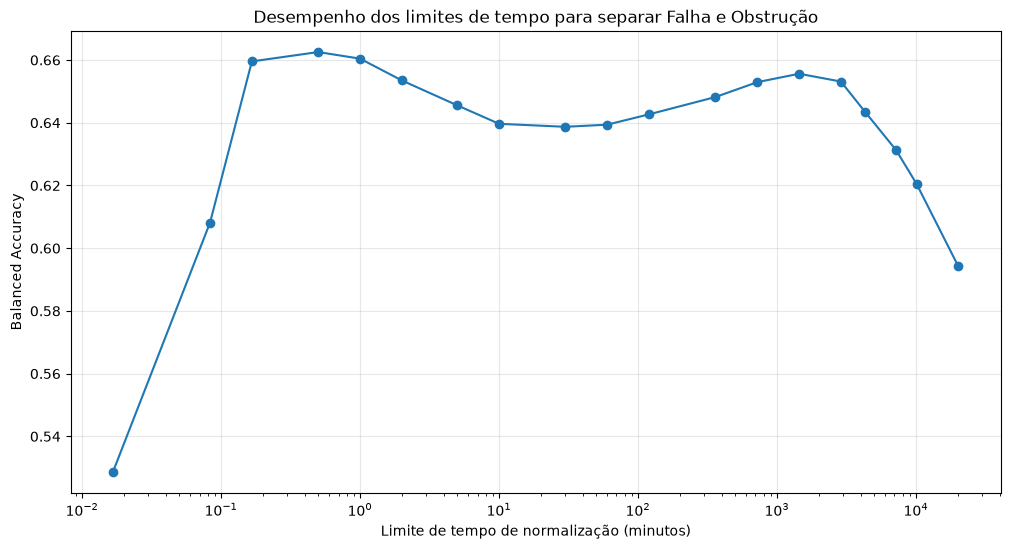

In [93]:

import matplotlib.pyplot as plt

# Ordenar pelo limite para o gráfico
grafico_limites = resultado_limites.sort_values("limite_min")

plt.figure(figsize=(12, 6))

plt.plot(
    grafico_limites["limite_min"],
    grafico_limites["balanced_accuracy"],
    marker="o"
)

plt.xscale("log")

plt.xlabel("Limite de tempo de normalização (minutos)")
plt.ylabel("Balanced Accuracy")
plt.title(
    "Desempenho dos limites de tempo para separar Falha e Obstrução"
)

plt.grid(True, alpha=0.3)

plt.show()

O segundo gráfico mostra por que um limite é melhor ou pior. A sensibilidade indica quantas falhas reais você consegue identificar. A especificidade indica quantas obstruções você consegue reconhecer corretamente. Normalmente existe um cabo de guerra: se o limite fica muito baixo, você chama muita coisa de falha. Se fica muito alto, deixa passar falhas verdadeiras. A balanced_accuracy procura o melhor equilíbrio entre os dois.

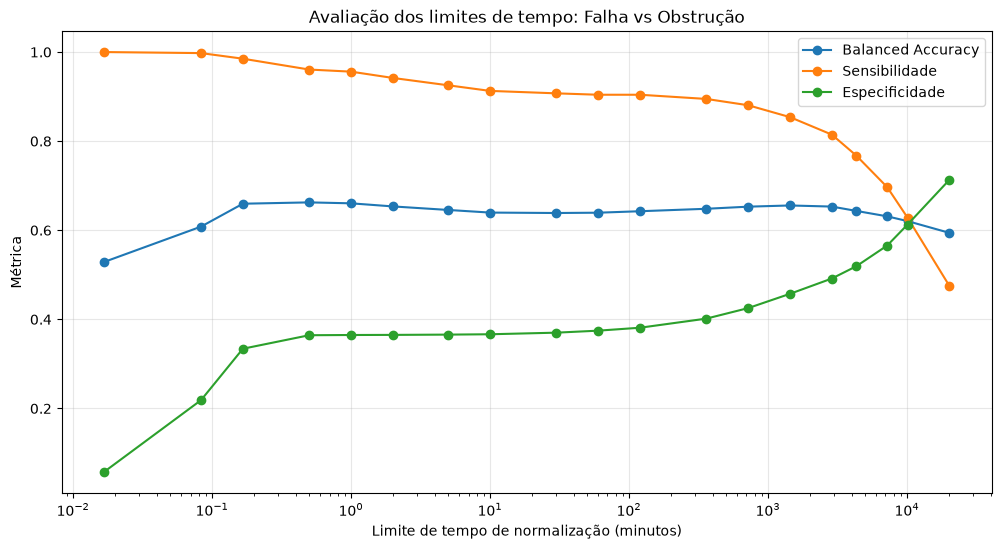

In [94]:
grafico_limites = resultado_limites.sort_values("limite_min")

plt.figure(figsize=(12, 6))

plt.plot(
    grafico_limites["limite_min"],
    grafico_limites["balanced_accuracy"],
    marker="o",
    label="Balanced Accuracy"
)

plt.plot(
    grafico_limites["limite_min"],
    grafico_limites["sensibilidade"],
    marker="o",
    label="Sensibilidade"
)

plt.plot(
    grafico_limites["limite_min"],
    grafico_limites["especificidade"],
    marker="o",
    label="Especificidade"
)

plt.xscale("log")

plt.xlabel("Limite de tempo de normalização (minutos)")
plt.ylabel("Métrica")
plt.title(
    "Avaliação dos limites de tempo: Falha vs Obstrução"
)

plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

In [95]:
melhor = resultado_limites.sort_values(
    "balanced_accuracy",
    ascending=False
).iloc[0]

print("Melhor limite encontrado:")
print(f"{melhor['limite_min']:.2f} minutos")

print("\nDesempenho:")
print(f"Balanced Accuracy: {melhor['balanced_accuracy']:.3f}")
print(f"Sensibilidade: {melhor['sensibilidade']:.3f}")
print(f"Especificidade: {melhor['especificidade']:.3f}")

print("\nMatriz de confusão:")
print("TP - Falhas identificadas corretamente:", int(melhor["TP"]))
print("TN - Obstruções identificadas corretamente:", int(melhor["TN"]))
print("FP - Obstruções classificadas como falha:", int(melhor["FP"]))
print("FN - Falhas classificadas como obstrução:", int(melhor["FN"]))

Melhor limite encontrado:
0.50 minutos

Desempenho:
Balanced Accuracy: 0.663
Sensibilidade: 0.961
Especificidade: 0.364

Matriz de confusão:
TP - Falhas identificadas corretamente: 1223
TN - Obstruções identificadas corretamente: 27502
FP - Obstruções classificadas como falha: 47976
FN - Falhas classificadas como obstrução: 50


Tempos muito curtos parecem ser bons indicadores de obstrução/evento transitório, mas um tempo longo, sozinho, não é suficiente para afirmar que houve falha no equipamento.

In [96]:
resultados_finos = []

# 0 a 10 minutos, de 1 em 1 segundo
limites_finos = np.arange(
    1/60,
    10 + 1/60,
    1/60
)

for limite in limites_finos:

    previsto = (
        teste_limite["tempo_normalizacao_min"] >= limite
    ).astype(int)

    real = teste_limite["falha_real"]

    tp = ((previsto == 1) & (real == 1)).sum()
    tn = ((previsto == 0) & (real == 0)).sum()
    fp = ((previsto == 1) & (real == 0)).sum()
    fn = ((previsto == 0) & (real == 1)).sum()

    sensibilidade = tp / (tp + fn)
    especificidade = tn / (tn + fp)

    balanced_accuracy = (
        sensibilidade + especificidade
    ) / 2

    precisao = (
        tp / (tp + fp)
        if (tp + fp) > 0
        else 0
    )

    resultados_finos.append({
        "limite_min": limite,
        "limite_seg": limite * 60,
        "TP": tp,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "sensibilidade": sensibilidade,
        "especificidade": especificidade,
        "precisao": precisao,
        "balanced_accuracy": balanced_accuracy
    })

resultado_fino = pd.DataFrame(resultados_finos)

In [97]:
melhor_fino = (
    resultado_fino
    .sort_values(
        "balanced_accuracy",
        ascending=False
    )
    .iloc[0]
)

print(f"Melhor limite: {melhor_fino['limite_seg']:.0f} segundos")
print(f"Balanced Accuracy: {melhor_fino['balanced_accuracy']:.3f}")
print(f"Sensibilidade: {melhor_fino['sensibilidade']:.3f}")
print(f"Especificidade: {melhor_fino['especificidade']:.3f}")
print(f"Precisão: {melhor_fino['precisao']:.3f}")

Melhor limite: 20 segundos
Balanced Accuracy: 0.664
Sensibilidade: 0.968
Especificidade: 0.361
Precisão: 0.025


In [98]:
from sklearn.metrics import roc_curve, roc_auc_score

y_real = teste_limite["falha_real"]

y_score = teste_limite["tempo_normalizacao_min"]

auc = roc_auc_score(
    y_real,
    y_score
)

fpr, tpr, thresholds = roc_curve(
    y_real,
    y_score
)

print(f"AUC: {auc:.3f}")

AUC: 0.669


In [99]:
from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)

y_real = teste_limite["falha_real"]
y_score = teste_limite["tempo_normalizacao_min"]

precision, recall, thresholds_pr = precision_recall_curve(
    y_real,
    y_score
)

average_precision = average_precision_score(
    y_real,
    y_score
)

print(
    f"Average Precision: {average_precision:.3f}"
)

Average Precision: 0.023


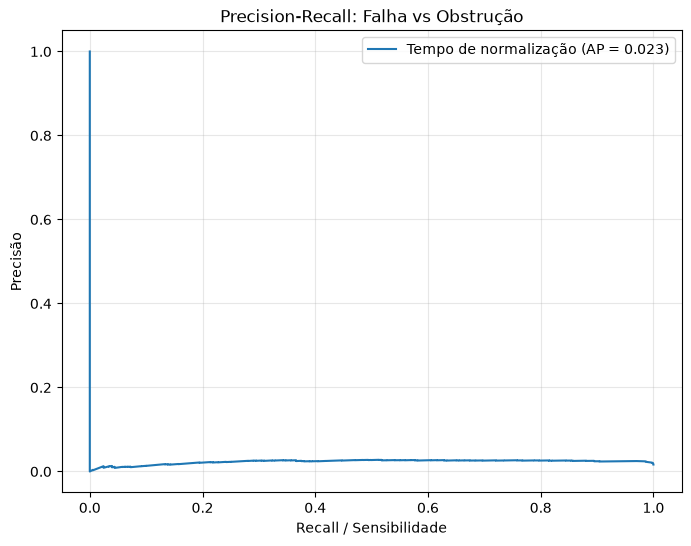

In [100]:
plt.figure(figsize=(8, 6))

plt.plot(
    recall,
    precision,
    label=f"Tempo de normalização (AP = {average_precision:.3f})"
)

plt.xlabel("Recall / Sensibilidade")
plt.ylabel("Precisão")

plt.title(
    "Precision-Recall: Falha vs Obstrução"
)

plt.legend()
plt.grid(alpha=0.3)

plt.show()

Finalização da hipótese de x tempo está relacionada com um problema não é possível identificar APENAS COM O TEMPO DE NORMALIZAÇÃO, porque não há dados suficientes para isso, já que a base é extremamente desbalanceada, com cerca de 1.273 falhas contra 75.478 obstruções, o que torna bem díficl equiparar isso!

In [101]:
resultado_pr = pd.DataFrame({
    "limite_min": thresholds_pr,
    "precision": precision[:-1],
    "recall": recall[:-1]
})

resultado_pr["limite_seg"] = (
    resultado_pr["limite_min"] * 60
)

resultado_pr = resultado_pr.sort_values(
    "precision",
    ascending=False
)

print(
    resultado_pr.head(20).to_string(index=False)
)

  limite_min  precision   recall  limite_seg
18198.223100   0.027816 0.512962 1091893.386
18198.204550   0.027814 0.512962 1091892.273
18197.924117   0.027813 0.512962 1091875.447
18197.855883   0.027812 0.512962 1091871.353
18193.781050   0.027811 0.512962 1091626.863
18191.328950   0.027810 0.512962 1091479.737
18187.757450   0.027809 0.512962 1091265.447
18186.285667   0.027807 0.512962 1091177.140
18185.434600   0.027806 0.512962 1091126.076
18182.094217   0.027805 0.512962 1090925.653
18182.054667   0.027804 0.512962 1090923.280
18181.760400   0.027803 0.512962 1090905.624
18181.296117   0.027801 0.512962 1090877.767
18178.257000   0.027800 0.512962 1090695.420
18171.035050   0.027799 0.512962 1090262.103
18167.924600   0.027798 0.512962 1090075.476
18166.661383   0.027797 0.512962 1089999.683
18165.734500   0.027796 0.512962 1089944.070
18164.786050   0.027794 0.512962 1089887.163
18163.717117   0.027793 0.512962 1089823.027


In [102]:
alta_precisao = resultado_pr[
    resultado_pr["precision"] >= 0.50
]

print(
    alta_precisao
    .sort_values("recall", ascending=False)
    .head(20)
    .to_string(index=False)
)

Empty DataFrame
Columns: [limite_min, precision, recall, limite_seg]
Index: []


Resultado da hipótese: O tempo de normalização apresenta associação com a ocorrência de falhas, porém não é suficiente, isoladamente, para distinguir falhas de obstruções. O melhor limiar encontrado na busca fina foi de aproximadamente 20 segundos, com sensibilidade de 96,8%, especificidade de 36,1% e precisão de apenas 2,5%. A AUC ROC foi de 0,669 e a Average Precision de 0,023. Além disso, nenhum limiar temporal alcançou precisão de 50%. Portanto, não foi identificado um tempo-limite capaz de classificar de forma confiável um evento como falha apenas pela duração da normalização.

# Passo 8. Investigação de tempos característicos por tipo de defeito

Como a primeira hipótese não encontrou um limite temporal confiável para separar obstruções de falhas, a análise passou a investigar uma segunda possibilidade:

> **Alguns tipos específicos de defeito apresentam um tempo de normalização característico?**

## Seleção dos registros utilizados

Para esse teste, foram utilizados apenas os alarmes que:

- haviam sido associados a uma avaria do SAP;
- possuíam `Defeito` identificado;
- apresentavam tempo de normalização calculável.

O objetivo era verificar se determinados tipos de defeito apresentavam distribuições temporais mais concentradas e, portanto, potencialmente reconhecíveis a partir do comportamento dos alarmes.

## Agrupamento por tipo de defeito

Os registros foram agrupados pela coluna `Defeito`.

Para cada categoria, foram calculadas medidas descritivas como:

- quantidade de ocorrências;
- média;
- mediana;
- mínimo;
- máximo;
- primeiro quartil;
- terceiro quartil;
- intervalo interquartil, **IQR**.

Essas estatísticas permitiram comparar tanto o valor típico do tempo de normalização quanto a dispersão dos registros em cada tipo de defeito.

## Construção do IQR relativo

Além do IQR tradicional, foi criada uma medida adicional denominada **IQR relativo**.

Ela foi calculada pela razão entre:

> **IQR / mediana**

Essa medida foi utilizada para identificar defeitos cujos tempos de normalização estavam relativamente concentrados em torno de um determinado valor.

Valores menores de IQR relativo indicavam, em princípio, uma menor dispersão proporcional dos tempos dentro daquela categoria de defeito.

## Primeiros resultados

Inicialmente, alguns resultados pareciam indicar padrões temporais bastante fortes.

Entre os principais casos encontrados estavam:

- **CORREIA DE TRAÇÃO DANIFICADA:** 44 registros, mediana de aproximadamente **58,7 dias** e IQR relativo de **0,013**;
- **PED CAN BOX SEM COMUNICAÇÃO:** 37 registros, mediana de aproximadamente **29,1 dias** e IQR relativo de **0,020**;
- **OBSTRUÇÃO DE FECHAMENTO:** 418 registros, mediana de aproximadamente **20,2 dias** e IQR relativo de **0,073**.

Esses resultados sugeriam, em um primeiro momento, que determinados defeitos poderiam apresentar uma espécie de **assinatura temporal**.

Ou seja, os alarmes associados a certos defeitos pareciam normalizar em faixas de tempo bastante específicas e pouco dispersas.

## Validação da independência dos eventos

Antes de aceitar essa interpretação, foi realizada uma verificação adicional.

O objetivo foi identificar quantos **eventos de manutenção independentes** existiam por trás de cada conjunto de alarmes.

Essa análise revelou um problema importante:

- os **44 registros** de `CORREIA DE TRAÇÃO DANIFICADA` correspondiam a apenas **2 manutenções independentes**;
- os **37 registros** de `PED CAN BOX SEM COMUNICAÇÃO` correspondiam a apenas **1 manutenção independente**;
- os **418 registros** de `OBSTRUÇÃO DE FECHAMENTO` correspondiam a apenas **16 manutenções independentes**.

## Identificação da pseudorrepetição

Os resultados mostraram que vários alarmes estavam sendo associados repetidamente à mesma ocorrência de manutenção.

Dessa forma, um único evento de manutenção poderia aparecer várias vezes na análise porque diferentes alarmes haviam sido vinculados a ele.

Isso fazia com que determinados tempos parecessem muito mais frequentes e concentrados do que realmente eram.

Em outras palavras, a análise estava tratando múltiplos alarmes associados à mesma manutenção como se fossem observações completamente independentes.

Esse fenômeno caracteriza um problema de:

> **pseudorrepetição**

A repetição de alarmes referentes ao mesmo evento acabava reforçando artificialmente determinadas faixas de tempo e podia produzir a falsa impressão de existência de uma assinatura temporal muito precisa para certos defeitos.

## Impacto na segunda hipótese

A identificação da pseudorrepetição impediu que os primeiros resultados fossem interpretados diretamente como evidência de tempos característicos por tipo de defeito.

Por exemplo, os 37 alarmes relacionados a `PED CAN BOX SEM COMUNICAÇÃO` não representavam 37 eventos independentes do mesmo defeito.

Na prática, todos estavam relacionados a uma única manutenção.

Portanto, a baixa dispersão observada nesse grupo não poderia ser utilizada como evidência suficiente de um padrão temporal recorrente.

## Resultado da etapa

Ao final desta etapa, ficou claro que **não era adequado tratar cada alarme associado como uma observação independente ao estudar características temporais de um defeito**.

A unidade de análise precisaria ser modificada.

Em vez de considerar diretamente cada alarme individual, seria necessário estruturar a análise de forma que cada ocorrência de manutenção tivesse um peso adequado, evitando que uma única avaria com muitos alarmes associados dominasse os resultados.

## Conclusão

Os primeiros resultados sugeriram a possível existência de tempos característicos para determinados tipos de defeito.

Entretanto, a validação do número de manutenções independentes revelou que parte dessa aparente concentração temporal era consequência da repetição de vários alarmes associados ao mesmo evento.

Assim, nesta etapa foi identificado um problema de **pseudorrepetição**, tornando necessária uma mudança na unidade de análise antes de continuar o teste da segunda hipótese.

A partir desse ponto, a análise deveria passar a considerar os **eventos de manutenção como unidades independentes**, ou utilizar algum tipo de agregação dos alarmes associados a cada manutenção, evitando conclusões artificiais produzidas pela repetição de um mesmo evento.

In [103]:
base_problemas = base_match[
    (base_match["associado_avaria"])
    & (base_match["Defeito"].notna())
    & (base_match["tempo_normalizacao_min"].notna())
].copy()

print("Eventos disponíveis:", len(base_problemas))

Eventos disponíveis: 8192


In [104]:
print(
    base_problemas["Defeito"]
    .value_counts()
    .head(30)
    .to_string()
)

Defeito
SENSOR FECHADO DESAJUSTADO             1598
SENSOR FECHADO AVARIADO                1217
SENSOR ABERTO DESAJUSTADO               736
SENSOR ABERTO AVARIADO                  568
OBSTRUCAO DE FECHAMENTO                 418
MCP TRAVADO                             382
SENSOR TRAVADO AVARIADO                 345
PERDA DE COMUNICACAO                    266
TROLLEY DESAJUSTADO                     266
MCP AVARIADO                            263
TRAVA AVARIADA                          232
PORTA DESAJUSTADA                       193
ATUADOR DA TRAVA DE PDM DESAJUSTADO     187
TRAVA DESAJUSTADA                       163
CABO-FIO ELETRICO ROMPIDO               152
MOTOR AVARIADO                          141
SENSOR DESTRAVADO DESAJUSTADO           132
BAIXA ISOLACAO                          125
SENSOR TRAVADO DESAJUSTADO               78
TRAVA DE SEGURANCA PDM DESAJUSTADA       70
MCP DESCONFIGURADO                       52
ATUADOR DA TRAVA DE PDM AVARIADO         51
TROLLEY AVARIADO        

In [105]:
tempo_por_defeito = (
    base_problemas
    .groupby("Defeito")["tempo_normalizacao_min"]
    .agg(
        quantidade="count",
        media="mean",
        mediana="median",
        minimo="min",
        maximo="max"
    )
)

tempo_por_defeito = tempo_por_defeito[
    tempo_por_defeito["quantidade"] >= 10
]

tempo_por_defeito = tempo_por_defeito.sort_values(
    "mediana"
)

print(tempo_por_defeito.to_string())

                                     quantidade         media       mediana        minimo         maximo
Defeito                                                                                                 
CABO-FIO ELETRICO ROMPIDO                   152   4095.357389      0.016883      0.015383   53253.119617
TROLLEY AVARIADO                             49   1322.147097      0.016933      0.006500   42779.072000
RUIDO ANORMAL                                36   8719.187984      0.125275      0.016383   63192.787333
TROLLEY DESAJUSTADO                         266     91.763362      5.961217      0.015833    1078.802550
ATUADOR DE PORTA AVARIADO                    10   1441.902102    121.512450      0.007000   10247.633667
OBSTRUCAO POR OBJETO ESTRANHO                15  13563.737813   2320.397550      0.016733   57893.321167
ATUADOR DE PORTA DESAJUSTADO                 43   5130.041169   3265.386283      0.083333   30919.519883
OBSTRUCAO DE ABERTURA                        15   6234.

In [106]:
q1 = (
    base_problemas
    .groupby("Defeito")["tempo_normalizacao_min"]
    .quantile(0.25)
)

q3 = (
    base_problemas
    .groupby("Defeito")["tempo_normalizacao_min"]
    .quantile(0.75)
)

tempo_por_defeito["q1"] = q1
tempo_por_defeito["q3"] = q3

tempo_por_defeito["IQR"] = (
    tempo_por_defeito["q3"]
    - tempo_por_defeito["q1"]
)

In [107]:
resultado_defeitos = (
    tempo_por_defeito
    .sort_values(
        ["IQR", "quantidade"],
        ascending=[True, False]
    )
)

print(resultado_defeitos.head(20).to_string())

                                  quantidade         media       mediana        minimo         maximo            q1            q3           IQR
Defeito                                                                                                                                        
CABO-FIO ELETRICO ROMPIDO                152   4095.357389      0.016883      0.015383   53253.119617      0.016450      0.054646      0.038196
TROLLEY AVARIADO                          49   1322.147097      0.016933      0.006500   42779.072000      0.016450      0.065667      0.049217
TROLLEY DESAJUSTADO                      266     91.763362      5.961217      0.015833    1078.802550      0.016667    107.000342    106.983675
PED CAN BOX SEM COMUNICACAO               37  41578.153384  41894.780783      0.083333   71133.393117  41416.977733  42235.129833    818.152100
ATUADOR DE PORTA AVARIADO                 10   1441.902102    121.512450      0.007000   10247.633667      0.014708    877.507700    877

In [108]:
resultado_defeitos["iqr_relativo"] = (
    resultado_defeitos["IQR"]
    / resultado_defeitos["mediana"]
)

resultado_defeitos_filtrado = (
    resultado_defeitos[
        (resultado_defeitos["quantidade"] >= 30)
        & (resultado_defeitos["mediana"] > 1)
    ]
    .sort_values("iqr_relativo")
)

print(
    resultado_defeitos_filtrado[
        [
            "quantidade",
            "mediana",
            "q1",
            "q3",
            "IQR",
            "iqr_relativo"
        ]
    ]
    .head(15)
    .to_string()
)

                                     quantidade       mediana            q1            q3           IQR  iqr_relativo
Defeito                                                                                                              
CORREIA DE TRACAO DANIFICADA                 44  84484.421642  83743.567038  84867.818992   1124.251954      0.013307
PED CAN BOX SEM COMUNICACAO                  37  41894.780783  41416.977733  42235.129833    818.152100      0.019529
OBSTRUCAO DE FECHAMENTO                     418  29022.503633  28003.316271  30111.895225   2108.578954      0.072653
ATUADOR DA TRAVA DE PDM DESAJUSTADO         187  33680.748383  26091.270025  48043.144575  21951.874550      0.651763
BAIXA ISOLACAO                              125  13822.252833   9069.142550  19144.925000  10075.782450      0.728954
AOU TRAVADO                                  46  38030.590217  20911.669454  53507.688617  32596.019163      0.857100
TRAVA AVARIADA                              232  40802.6

In [109]:
resultado_defeitos_filtrado["mediana_dias"] = (
    resultado_defeitos_filtrado["mediana"] / 1440
)

resultado_defeitos_filtrado["q1_dias"] = (
    resultado_defeitos_filtrado["q1"] / 1440
)

resultado_defeitos_filtrado["q3_dias"] = (
    resultado_defeitos_filtrado["q3"] / 1440
)

print(
    resultado_defeitos_filtrado[
        [
            "quantidade",
            "mediana_dias",
            "q1_dias",
            "q3_dias",
            "iqr_relativo"
        ]
    ]
    .head(15)
    .to_string()
)

                                     quantidade  mediana_dias    q1_dias    q3_dias  iqr_relativo
Defeito                                                                                          
CORREIA DE TRACAO DANIFICADA                 44     58.669737  58.155255  58.935985      0.013307
PED CAN BOX SEM COMUNICACAO                  37     29.093598  28.761790  29.329951      0.019529
OBSTRUCAO DE FECHAMENTO                     418     20.154516  19.446747  20.911038      0.072653
ATUADOR DA TRAVA DE PDM DESAJUSTADO         187     23.389409  18.118938  33.363295      0.651763
BAIXA ISOLACAO                              125      9.598787   6.298016  13.295087      0.728954
AOU TRAVADO                                  46     26.410132  14.521993  37.158117      0.857100
TRAVA AVARIADA                              232     28.335199  12.713689  38.621190      0.914322
SENSOR DESTRAVADO DESAJUSTADO               132     11.663805   3.034435  14.512903      0.984110
SENSOR ABERTO AVARIA

In [110]:
base_problemas["evento_manutencao"] = (
    base_problemas["estacao_key"].astype(str)
    + "_"
    + base_problemas["plataforma_key"].astype(str)
    + "_"
    + base_problemas["porta_key"].astype(str)
    + "_"
    + base_problemas["inicio_avaria_dt"].astype(str)
    + "_"
    + base_problemas["fim_avaria_dt"].astype(str)
    + "_"
    + base_problemas["Defeito"].astype(str)
)

# Passo 9. Correção da pseudorrepetição e reavaliação da hipótese por defeito

Após identificar que vários alarmes estavam associados à mesma manutenção, a unidade de análise foi alterada.

## Mudança da unidade de análise

Em vez de considerar cada alarme como uma observação independente, passou-se a considerar:

> **1 manutenção = 1 observação**

Essa mudança foi necessária para evitar que uma única ocorrência de manutenção, associada a vários alarmes, tivesse um peso excessivo na análise.

## Agregação dos alarmes por manutenção

Para cada evento de manutenção, os alarmes associados foram agrupados e resumidos por meio de medidas como:

- tempo mediano de normalização;
- tempo mínimo de normalização;
- tempo máximo de normalização;
- quantidade de alarmes associados.

Dessa forma, cada manutenção passou a contribuir apenas uma vez para a análise, independentemente da quantidade de alarmes relacionados a ela.

## Reavaliação por tipo de defeito

Com essa nova estrutura, a análise por `Defeito` foi repetida utilizando apenas eventos de manutenção independentes.

Foram novamente avaliadas medidas como:

- quantidade de eventos;
- mediana;
- primeiro quartil;
- terceiro quartil;
- intervalo interquartil, **IQR**;
- **IQR relativo**.

O IQR relativo continuou sendo utilizado como medida de concentração temporal, calculado por:

> **IQR / mediana**

Quanto menor esse valor, maior seria, em princípio, a concentração dos tempos de normalização em torno de um valor típico.

## Critério mínimo de quantidade de eventos

Para evitar conclusões baseadas em categorias com poucas observações, foram analisados principalmente os defeitos com pelo menos:

> **10 eventos de manutenção independentes**

Esse critério aumentou a robustez da comparação e reduziu o risco de interpretar padrões produzidos por amostras muito pequenas.

## Resultados após a correção

Após a remoção da pseudorrepetição, os padrões temporais que anteriormente pareciam muito concentrados praticamente desapareceram.

O caso com menor dispersão relativa encontrado foi:

### `TROLLEY DESAJUSTADO`

- **22 eventos independentes**;
- mediana de aproximadamente **7,5 minutos**;
- IQR relativo de aproximadamente **1,06**.

Embora esse tenha sido o melhor resultado entre os defeitos analisados, o IQR relativo ainda indicava uma dispersão considerável em relação à mediana.

## Exemplos de outros defeitos

Os demais defeitos apresentaram dispersões relativas ainda maiores.

Alguns exemplos foram:

- `SENSOR FECHADO AVARIADO`: IQR relativo de aproximadamente **1,48**;
- `SENSOR TRAVADO AVARIADO`: aproximadamente **1,79**;
- `SENSOR FECHADO DESAJUSTADO`: aproximadamente **2,53**;
- `MCP AVARIADO`: aproximadamente **4,42**;
- `MOTOR AVARIADO`: aproximadamente **16,20**.

Esses valores mostram que, dentro de um mesmo tipo de defeito, os tempos de normalização podiam variar de forma significativa.

## Impacto da correção da pseudorrepetição

A comparação entre os resultados anteriores e os obtidos nesta etapa mostrou que a aparente existência de assinaturas temporais muito precisas estava sendo influenciada pela repetição de vários alarmes associados à mesma manutenção.

Quando cada manutenção passou a ser tratada como uma única observação independente, essa concentração praticamente desapareceu.

Isso reforçou a importância de escolher corretamente a unidade de análise antes de interpretar padrões estatísticos.

## Resultado da segunda hipótese

A segunda hipótese investigava se determinados tipos de defeito apresentavam um tempo de normalização característico e relativamente estável.

Após a correção da pseudorrepetição, essa hipótese também foi considerada:

> **Não sustentada de forma robusta pelos dados**

Não foi encontrada evidência suficiente de que um determinado defeito apresentasse um único tempo de normalização suficientemente estável para funcionar como uma assinatura temporal confiável.

## Investigação adicional de `TROLLEY DESAJUSTADO`

Apesar da rejeição geral da hipótese, o defeito `TROLLEY DESAJUSTADO` apresentou a menor dispersão relativa entre os casos analisados.

Por esse motivo, ele foi mantido como candidato para uma investigação adicional.

O objetivo dessa análise posterior seria verificar se, mesmo sem representar uma assinatura temporal universal, esse defeito apresentava algum comportamento específico que justificasse uma avaliação mais detalhada.

## Conclusão

A correção da pseudorrepetição alterou de forma importante os resultados da análise por defeito.

Quando cada manutenção passou a representar uma única observação, os tempos de normalização mostraram grande variabilidade dentro das próprias categorias de defeito.

Assim, não foi encontrada evidência robusta de que os defeitos possuíssem **tempos característicos e estáveis de normalização**.

O caso de `TROLLEY DESAJUSTADO` permaneceu como o exemplo com menor dispersão relativa e foi selecionado para uma investigação complementar na etapa seguinte.

In [111]:
validacao_defeitos = (
    base_problemas
    .groupby("Defeito")
    .agg(
        registros=("tempo_normalizacao_min", "count"),
        eventos_manutencao=("evento_manutencao", "nunique"),
        estacoes=("estacao_key", "nunique"),
        portas=("porta_key", "nunique")
    )
    .sort_values("registros", ascending=False)
)

print(
    validacao_defeitos.loc[
        [
            "CORREIA DE TRACAO DANIFICADA",
            "PED CAN BOX SEM COMUNICACAO",
            "OBSTRUCAO DE FECHAMENTO"
        ]
    ].to_string()
)

                              registros  eventos_manutencao  estacoes  portas
Defeito                                                                      
CORREIA DE TRACAO DANIFICADA         44                   2         2       2
PED CAN BOX SEM COMUNICACAO          37                   1         1       1
OBSTRUCAO DE FECHAMENTO             418                  16         6      12


a hipótese está necessariamente errada, mas a evidência que parecia sustentá-la era artificialmente inflada. Os números pareciam bacanas, mas todas os registros são basicamentes no mesmo evento/manutenção.

In [112]:
eventos_manutencao = (
    base_problemas
    .groupby(
        [
            "evento_manutencao",
            "Defeito"
        ],
        as_index=False
    )
    .agg(
        tempo_mediano_normalizacao=(
            "tempo_normalizacao_min",
            "median"
        ),
        tempo_min_normalizacao=(
            "tempo_normalizacao_min",
            "min"
        ),
        tempo_max_normalizacao=(
            "tempo_normalizacao_min",
            "max"
        ),
        quantidade_alarmes=(
            "tempo_normalizacao_min",
            "count"
        ),
        estacao=(
            "estacao_key",
            "first"
        ),
        porta=(
            "porta_key",
            "first"
        )
    )
)

In [113]:
print(
    "Alarmes antes:",
    len(base_problemas)
)

print(
    "Manutenções independentes:",
    len(eventos_manutencao)
)

Alarmes antes: 8192
Manutenções independentes: 682


In [114]:
eventos_por_defeito = (
    eventos_manutencao["Defeito"]
    .value_counts()
)

print(
    eventos_por_defeito
    .head(30)
    .to_string()
)

Defeito
SENSOR FECHADO DESAJUSTADO             110
SENSOR FECHADO AVARIADO                 77
MCP TRAVADO                             52
MCP AVARIADO                            36
SENSOR ABERTO DESAJUSTADO               29
MOTOR AVARIADO                          29
SENSOR TRAVADO AVARIADO                 24
SENSOR TRAVADO DESAJUSTADO              23
PORTA DESAJUSTADA                       23
TROLLEY DESAJUSTADO                     22
TRAVA DESAJUSTADA                       19
PERDA DE COMUNICACAO                    19
TRAVA AVARIADA                          16
ATUADOR DE PORTA DESAJUSTADO            16
ATUADOR DA TRAVA DE PDM DESAJUSTADO     16
OBSTRUCAO DE FECHAMENTO                 16
SENSOR ABERTO AVARIADO                  15
MCP DESCONFIGURADO                      14
SENSOR DESTRAVADO DESAJUSTADO           12
BAIXA ISOLACAO                          11
TRAVA DE SEGURANCA PDM DESAJUSTADA       8
RUIDO ANORMAL                            8
TROLLEY AVARIADO                         8
COR

In [115]:
defeitos_validos = (
    eventos_por_defeito[
        eventos_por_defeito >= 10
    ]
    .index
)

eventos_validos = eventos_manutencao[
    eventos_manutencao["Defeito"]
    .isin(defeitos_validos)
].copy()

In [116]:
print(
    "Defeitos com pelo menos 10 eventos:",
    eventos_validos["Defeito"].nunique()
)

print(
    "Eventos utilizados:",
    len(eventos_validos)
)

Defeitos com pelo menos 10 eventos: 20
Eventos utilizados: 579


In [117]:
tempo_evento_defeito = (
    eventos_validos
    .groupby("Defeito")[
        "tempo_mediano_normalizacao"
    ]
    .agg(
        quantidade_eventos="count",
        media="mean",
        mediana="median",
        minimo="min",
        maximo="max"
    )
)

In [118]:
tempo_evento_defeito["q1"] = (
    eventos_validos
    .groupby("Defeito")[
        "tempo_mediano_normalizacao"
    ]
    .quantile(0.25)
)

tempo_evento_defeito["q3"] = (
    eventos_validos
    .groupby("Defeito")[
        "tempo_mediano_normalizacao"
    ]
    .quantile(0.75)
)

In [119]:
tempo_evento_defeito["IQR"] = (
    tempo_evento_defeito["q3"]
    - tempo_evento_defeito["q1"]
)

In [120]:
tempo_evento_defeito["iqr_relativo"] = (
    tempo_evento_defeito["IQR"]
    / tempo_evento_defeito["mediana"]
)

In [121]:
resultado_eventos = (
    tempo_evento_defeito
    .sort_values("iqr_relativo")
)

print(
    resultado_eventos
    .head(20)
    .to_string()
)

                                     quantidade_eventos         media       mediana     minimo         maximo           q1            q3           IQR  iqr_relativo
Defeito                                                                                                                                                             
TROLLEY DESAJUSTADO                                  22     21.944998      7.502075   0.016433     190.667025     0.016950      7.954646      7.937696      1.058067
SENSOR FECHADO AVARIADO                              77  21716.302984  17798.126433   0.108475   90413.986950  4088.589433  30409.202550  26320.613117      1.478842
SENSOR TRAVADO AVARIADO                              24  24846.950736  18295.798029   0.083067   76044.924833  5069.901942  37868.468131  32798.566190      1.792683
ATUADOR DE PORTA DESAJUSTADO                         16   4732.869724   3459.709617   0.083333   26740.382433     8.671012   6267.793504   6259.122492      1.809147
SENSOR TRA

# Passo 10. Investigação do caso `TROLLEY DESAJUSTADO` e identificação de efeito de estação

Como `TROLLEY DESAJUSTADO` foi o defeito com menor dispersão relativa após a correção da pseudorrepetição, ele foi analisado separadamente para verificar se realmente existia um padrão temporal característico.

## Análise dos eventos de `TROLLEY DESAJUSTADO`

Foram observados **22 eventos independentes** associados a esse defeito.

Ao ordenar os tempos medianos de normalização, percebeu-se que os valores não estavam concentrados em torno de um único intervalo.

Na prática, surgiram aproximadamente três grupos distintos:

- eventos com normalização praticamente instantânea, próximos de **1 segundo**;
- eventos com duração entre aproximadamente **6 e 11 minutos**;
- poucos eventos com tempos muito maiores, entre aproximadamente **100 e 190 minutos**.

## Interpretação da distribuição

Esse resultado mostrou que a mediana de aproximadamente **7,5 minutos** não representava adequadamente todos os eventos.

Apesar de indicar um valor central, ela escondia comportamentos temporais bastante diferentes dentro do mesmo tipo de defeito.

Portanto, mesmo `TROLLEY DESAJUSTADO`, que havia apresentado a menor dispersão relativa na etapa anterior, **não possuía uma única assinatura temporal consistente**.

## Identificação de concentração por estação

Durante a investigação desse defeito, surgiu outro padrão importante.

Dos **22 eventos independentes** analisados:

> **21 pertenciam à estação HIG**

Essa forte concentração levantou a possibilidade de que o comportamento temporal observado não estivesse necessariamente relacionado apenas ao tipo de defeito.

Em vez disso, poderia existir um efeito associado à própria **estação**.

## Mudança do foco da análise

A partir dessa descoberta, a investigação deixou de considerar apenas a variável `Defeito` e passou a avaliar se existiam diferenças sistemáticas no tempo de normalização entre diferentes estações.

A hipótese exploratória passou a ser:

> **O comportamento temporal dos alarmes pode variar de acordo com a estação?**

Essa mudança de foco buscou verificar se determinadas estações apresentavam padrões próprios de duração ou maior frequência de eventos prolongados.

## Análise inicial por estação

Foi então analisada a distribuição temporal dos eventos por estação.

Um dos indicadores utilizados nessa primeira avaliação foi a proporção de casos com duração superior a:

> **24 horas**

Essa comparação revelou diferenças relevantes entre as estações.

Algumas apresentavam proporções maiores de eventos prolongados, enquanto outras concentravam mais ocorrências de curta duração.

## Resultado da etapa

Os resultados indicaram que a variável `estacao_key` poderia estar associada a diferenças importantes no comportamento temporal dos alarmes.

Essa descoberta também mostrou que parte dos padrões inicialmente atribuídos ao defeito poderia, na realidade, estar sendo influenciada pela concentração dos eventos em uma determinada estação.

## Conclusão

A investigação de `TROLLEY DESAJUSTADO` mostrou que o defeito não apresentava uma assinatura temporal única e consistente.

Além disso, a concentração de **21 dos 22 eventos na estação HIG** revelou um possível **efeito de estação**, abrindo uma nova direção para a análise.

A partir desse ponto, tornou-se necessário investigar de forma mais sistemática se as diferenças de tempo de normalização estavam relacionadas à localização da ocorrência, especialmente à estação, e não apenas ao tipo de defeito.

In [122]:
trolley = eventos_validos[
    eventos_validos["Defeito"] == "TROLLEY DESAJUSTADO"
].copy()

print(
    trolley[
        [
            "tempo_mediano_normalizacao",
            "quantidade_alarmes",
            "estacao",
            "porta"
        ]
    ]
    .sort_values("tempo_mediano_normalizacao")
    .to_string(index=False)
)

 tempo_mediano_normalizacao  quantidade_alarmes estacao  porta
                   0.016433                   1     HIG      6
                   0.016667                   1     HIG     17
                   0.016667                  18     HIG     19
                   0.016667                  23     HIG      4
                   0.016667                   1     HIG      9
                   0.016950                  21     HIG     11
                   0.016950                  42     HIG     17
                   0.017167                   2     HIG      1
                   0.083617                   1     FRA     12
                   5.960933                   9     HIG     18
                   7.501933                   8     HIG      8
                   7.502217                   6     HIG     22
                   7.502358                   6     HIG     21
                   7.954433                   5     HIG      6
                   7.954433                  11     HIG

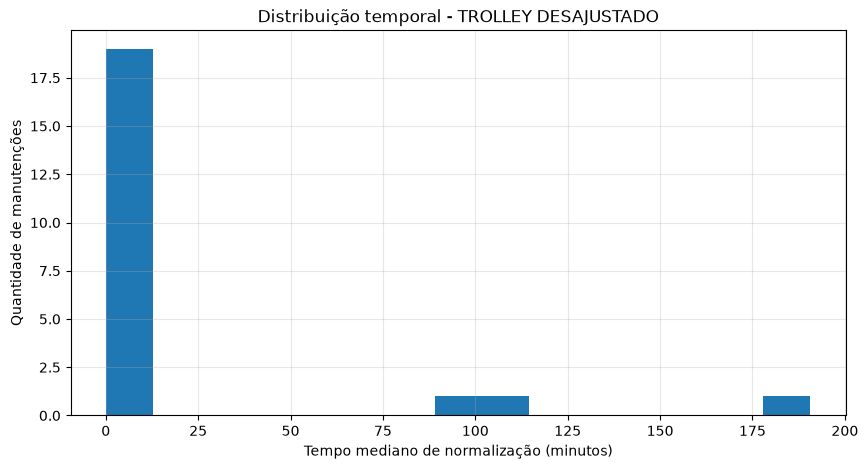

In [123]:
plt.figure(figsize=(10, 5))

plt.hist(
    trolley["tempo_mediano_normalizacao"],
    bins=15
)

plt.xlabel("Tempo mediano de normalização (minutos)")
plt.ylabel("Quantidade de manutenções")
plt.title("Distribuição temporal - TROLLEY DESAJUSTADO")

plt.grid(alpha=0.3)
plt.show()

In [124]:
trolley["faixa_temporal"] = pd.cut(
    trolley["tempo_mediano_normalizacao"],
    bins=[-1, 1, 15, float("inf")],
    labels=[
        "< 1 min",
        "1-15 min",
        "> 15 min"
    ]
)

print(
    trolley["faixa_temporal"]
    .value_counts()
    .sort_index()
)

faixa_temporal
< 1 min      9
1-15 min    10
> 15 min     3
Name: count, dtype: int64


In [125]:
hig = eventos_validos[
    eventos_validos["estacao"] == "HIG"
].copy()

hig["faixa_temporal"] = pd.cut(
    hig["tempo_mediano_normalizacao"],
    bins=[
        -1,
        1,
        5,
        15,
        60,
        180,
        1440,
        float("inf")
    ],
    labels=[
        "< 1 min",
        "1-5 min",
        "5-15 min",
        "15-60 min",
        "1-3 h",
        "3-24 h",
        "> 24 h"
    ]
)

tabela_hig = pd.crosstab(
    hig["Defeito"],
    hig["faixa_temporal"]
)

print(
    tabela_hig
    .sort_values("< 1 min", ascending=False)
    .head(20)
    .to_string()
)

faixa_temporal                       < 1 min  5-15 min  15-60 min  1-3 h  3-24 h  > 24 h
Defeito                                                                                 
TROLLEY DESAJUSTADO                        8        10          0      2       1       0
PORTA DESAJUSTADA                          4         3          0      0       0      12
MCP AVARIADO                               3         0          0      0       0       3
MOTOR AVARIADO                             3         0          0      0       2       4
SENSOR ABERTO DESAJUSTADO                  2         0          0      0       0       1
SENSOR ABERTO AVARIADO                     2         0          0      0       0       1
PERDA DE COMUNICACAO                       2         0          0      0       0       1
SENSOR TRAVADO DESAJUSTADO                 1         0          0      0       0       2
MCP TRAVADO                                1         0          0      0       4      14
SENSOR FECHADO DESAJU

achamos uma hipótese mais relevante: HIG apresenta tempos de normalização significativamente maiores que as outras estações?

In [126]:
eventos_manutencao["acima_24h"] = (
    eventos_manutencao["tempo_mediano_normalizacao"] > 1440
)

resumo_estacao = (
    eventos_manutencao
    .groupby("estacao")["tempo_mediano_normalizacao"]
    .agg(
        eventos="count",
        media="mean",
        mediana="median"
    )
)

resumo_estacao["q1"] = (
    eventos_manutencao
    .groupby("estacao")["tempo_mediano_normalizacao"]
    .quantile(0.25)
)

resumo_estacao["q3"] = (
    eventos_manutencao
    .groupby("estacao")["tempo_mediano_normalizacao"]
    .quantile(0.75)
)

resumo_estacao["pct_acima_24h"] = (
    eventos_manutencao
    .groupby("estacao")["acima_24h"]
    .mean() * 100
)

resumo_estacao = resumo_estacao.sort_values(
    "pct_acima_24h",
    ascending=False
)

print(resumo_estacao.to_string())


         eventos         media       mediana           q1            q3  pct_acima_24h
estacao                                                                               
FRA          173  16484.038378  11456.269383  2666.448717  23622.303667      79.190751
FAL           91  21082.216504   4866.260033   819.949217  35730.009854      69.230769
BUT          167  16626.586565   5729.035950    10.083200  24849.202242      64.071856
LUZ           72  13683.257175   4762.012496     0.281304  15696.850848      56.944444
HIG          175   9062.781573   2393.252200     7.003700  12892.717792      53.714286
FRE            4      2.242233      0.024858     0.016596      2.250496       0.000000


In [127]:
comparacao_hig = eventos_manutencao.copy()

comparacao_hig["grupo_estacao"] = "Outras"

comparacao_hig.loc[
    comparacao_hig["estacao"] == "HIG",
    "grupo_estacao"
] = "HIG"

tempo_hig_defeito = (
    comparacao_hig
    .groupby(
        ["Defeito", "grupo_estacao"]
    )["tempo_mediano_normalizacao"]
    .agg(
        eventos="count",
        mediana="median"
    )
    .reset_index()
)

print(
    tempo_hig_defeito
    .sort_values(
        ["Defeito", "grupo_estacao"]
    )
    .to_string(index=False)
)

                            Defeito grupo_estacao  eventos      mediana
    ALTA TEMPERATURA EM COMPONENTES        Outras        1  3739.013333
                        AOU TRAVADO        Outras        2 22174.379775
   ATUADOR DA TRAVA DE PDM AVARIADO        Outras        6  9989.296417
ATUADOR DA TRAVA DE PDM DESAJUSTADO           HIG        4  9285.918783
ATUADOR DA TRAVA DE PDM DESAJUSTADO        Outras       12  6289.206421
          ATUADOR DE PORTA AVARIADO           HIG        5     0.026833
       ATUADOR DE PORTA DESAJUSTADO           HIG        1  5187.112667
       ATUADOR DE PORTA DESAJUSTADO        Outras       15  3263.449283
                     BAIXA ISOLACAO           HIG        1  3410.788050
                     BAIXA ISOLACAO        Outras       10  9416.150083
          CABO-FIO ELETRICO ROMPIDO           HIG        2     0.116733
          CABO-FIO ELETRICO ROMPIDO        Outras        3 18761.556167
          CARRO DESLIZANTE AVARIADO        Outras        1     1

Com a base bem filtrada, temos um padrão: quase todos os problemas que tem acima de 10 eventos, demoram mais de 24h para resolver

In [128]:
tabela_estacoes_24h = pd.crosstab(
    eventos_manutencao["estacao"],
    eventos_manutencao["acima_24h"]
)

tabela_estacoes_24h.columns = [
    "ate_24h",
    "acima_24h"
]

print(tabela_estacoes_24h)

         ate_24h  acima_24h
estacao                    
BUT           60        107
FAL           28         63
FRA           36        137
FRE            4          0
HIG           81         94
LUZ           31         41


# Passo 11. Comparação geral entre Alarmes PSD, ZM01 e ZM02 por estação

Depois de identificar que a estação poderia influenciar o comportamento temporal dos eventos, foi realizada uma comparação mais ampla entre as três fontes de dados:

- **Alarmes PSD**
- **SAP ZM01**
- **SAP ZM02**

## Construção de uma base comum

Para permitir a comparação entre as fontes, foi criada uma estrutura padronizada contendo, para cada registro:

- estação;
- fonte do dado;
- duração do evento em horas.

Essa padronização permitiu analisar conjuntamente registros originados de sistemas diferentes, preservando a identificação da fonte de cada ocorrência.

## Cálculo da duração por fonte

A duração foi calculada respeitando o significado temporal específico de cada base.

### Alarmes PSD

Nos Alarmes PSD, a duração foi calculada pela diferença entre:

> `Horário da Normalizacao` - `Horário do Alarme`

Esse intervalo representa o período entre o surgimento do alarme e sua normalização.

### SAP ZM01

Na base ZM01, a duração foi calculada pela diferença entre:

> `fim_avaria_dt` - `inicio_avaria_dt`

Esse intervalo representa a duração registrada de uma avaria corretiva emergencial.

### SAP ZM02

Na base ZM02, a duração também foi calculada pela diferença entre:

> `fim_avaria_dt` - `inicio_avaria_dt`

Nesse caso, porém, o registro pertence a uma manutenção corretiva programada.

## Concatenação das fontes

Após a padronização, os registros das três fontes foram concatenados em uma única base.

Essa estrutura reuniu:

- **161.813 registros** no total;
- **124.196 registros** com duração calculável;
- **37.617 registros** sem informação temporal suficiente para determinar a duração.

Os registros sem duração válida foram preservados na estrutura geral, mas não puderam ser utilizados nas análises que dependiam diretamente do tempo do evento.

## Identificação de eventos superiores a 24 horas

Em seguida, foi criado um indicador para identificar eventos cuja duração ultrapassava:

> **24 horas**

Esse indicador permitiu comparar a proporção de eventos prolongados entre diferentes estações e fontes.

## Diferenças entre as fontes

A análise revelou comportamentos temporais distintos entre as três bases.

De forma geral:

- as ordens **ZM01** apresentavam uma baixa proporção de eventos com duração superior a 24 horas;
- a **ZM02** apresentava proporções significativamente maiores de eventos acima de 24 horas;
- os **Alarmes PSD** apresentavam forte variação entre as estações.

Essas diferenças indicaram que a distribuição temporal dos eventos dependia não apenas da estação, mas também da natureza da fonte analisada.

## Diferença de significado operacional

Esse resultado reforçou uma limitação importante da comparação direta entre as três bases.

Apesar de todas possuírem uma variável que pode ser expressa como duração, essa duração representa fenômenos operacionais diferentes.

Por exemplo:

- um **alarme PSD ativo por 24 horas** representa um evento que permaneceu sem normalização durante esse período;
- uma **avaria emergencial ZM01 de 24 horas** representa uma ocorrência corretiva cujo intervalo registrado entre início e encerramento foi de 24 horas;
- uma **manutenção programada ZM02 de 24 horas** representa uma intervenção de natureza planejada com duração registrada de 24 horas.

Portanto, valores temporais semelhantes não significam necessariamente eventos equivalentes do ponto de vista operacional.

## Impacto na estratégia de análise

A comparação mostrou que não seria adequado interpretar as três fontes como se representassem exatamente o mesmo fenômeno temporal.

Misturar diretamente as distribuições poderia ocultar diferenças importantes relacionadas à natureza de cada sistema e de cada tipo de registro.

Por esse motivo, decidiu-se aprofundar a análise das fontes de forma separada.

## Foco nos Alarmes PSD

Entre as três bases, os **Alarmes PSD** apresentaram as diferenças mais marcantes entre as estações.

Esse comportamento tornou a base particularmente relevante para investigar a hipótese de um possível efeito associado à localização.

Assim, as etapas seguintes passaram a concentrar a análise principalmente nos Alarmes PSD, comparando de forma mais detalhada o comportamento temporal entre as diferentes estações.

## Conclusão

A comparação conjunta entre Alarmes PSD, ZM01 e ZM02 mostrou que as três fontes apresentam distribuições temporais distintas e representam fenômenos operacionais diferentes.

Por esse motivo, a duração não deveria ser comparada de forma indiscriminada entre as bases.

Ao mesmo tempo, a forte variação observada nos **Alarmes PSD entre as estações** reforçou a necessidade de investigar separadamente essa fonte, direcionando a análise seguinte para a identificação de possíveis padrões temporais específicos por estação.

In [129]:
# ============================================================
# HIPÓTESE:
# Existem estações em que os eventos tendem a permanecer
# abertos por mais de 24 horas?
#
# Fontes utilizadas:
# - Alarmes PSD
# - SAP ZM01 (corretiva emergencial)
# - SAP ZM02 (corretiva programada)
# ============================================================


# ============================================================
# 1. ALARMES PSD
# ============================================================

base_alarmes = alarmes.copy()

base_alarmes["estacao"] = (
    base_alarmes["Estação"]
    .astype("string")
    .str.strip()
    .str.upper()
)

inicio_alarme = pd.to_datetime(
    base_alarmes["Horário do Alarme"],
    errors="coerce"
)

fim_alarme = pd.to_datetime(
    base_alarmes["Horário da Normalizacao"],
    errors="coerce"
)

base_alarmes["duracao_h"] = (
    (fim_alarme - inicio_alarme)
    .dt.total_seconds()
    / 3600
)

base_alarmes["fonte"] = "Alarme PSD"


# ============================================================
# 2. SAP ZM01
# ============================================================

base_zm01 = correcao_emergencial.copy()

base_zm01["estacao"] = (
    base_zm01["Local de Instalação"]
    .astype("string")
    .str.extract(
        r"PSD-([A-Z]{3})",
        expand=False
    )
)

data_inicio_zm01 = pd.to_datetime(
    base_zm01["Início avaria"],
    dayfirst=True,
    errors="coerce"
)

hora_inicio_zm01 = pd.to_timedelta(
    base_zm01["Hora início avaria"].astype(str),
    errors="coerce"
)

data_fim_zm01 = pd.to_datetime(
    base_zm01["Fim da avaria"],
    dayfirst=True,
    errors="coerce"
)

hora_fim_zm01 = pd.to_timedelta(
    base_zm01["Hora do fim da avaria"].astype(str),
    errors="coerce"
)

inicio_zm01 = (
    data_inicio_zm01.dt.normalize()
    + hora_inicio_zm01
)

fim_zm01 = (
    data_fim_zm01.dt.normalize()
    + hora_fim_zm01
)

base_zm01["duracao_h"] = (
    (fim_zm01 - inicio_zm01)
    .dt.total_seconds()
    / 3600
)

base_zm01["fonte"] = "SAP ZM01"


# ============================================================
# 3. SAP ZM02
# ============================================================

base_zm02 = correcao_programada.copy()

base_zm02["estacao"] = (
    base_zm02["Local de Instalação"]
    .astype("string")
    .str.extract(
        r"PSD-([A-Z]{3})",
        expand=False
    )
)

data_inicio_zm02 = pd.to_datetime(
    base_zm02["Início avaria"],
    dayfirst=True,
    errors="coerce"
)

hora_inicio_zm02 = pd.to_timedelta(
    base_zm02["Hora início avaria"].astype(str),
    errors="coerce"
)

data_fim_zm02 = pd.to_datetime(
    base_zm02["Fim da avaria"],
    dayfirst=True,
    errors="coerce"
)

hora_fim_zm02 = pd.to_timedelta(
    base_zm02["Hora do fim da avaria"].astype(str),
    errors="coerce"
)

inicio_zm02 = (
    data_inicio_zm02.dt.normalize()
    + hora_inicio_zm02
)

fim_zm02 = (
    data_fim_zm02.dt.normalize()
    + hora_fim_zm02
)

base_zm02["duracao_h"] = (
    (fim_zm02 - inicio_zm02)
    .dt.total_seconds()
    / 3600
)

base_zm02["fonte"] = "SAP ZM02"


# ============================================================
# 4. JUNTAR TODAS AS FONTES
# ============================================================

eventos_gerais = pd.concat(
    [
        base_alarmes[
            ["estacao", "fonte", "duracao_h"]
        ],
        base_zm01[
            ["estacao", "fonte", "duracao_h"]
        ],
        base_zm02[
            ["estacao", "fonte", "duracao_h"]
        ]
    ],
    ignore_index=True
)


# ============================================================
# 5. IDENTIFICAR DURAÇÕES INVÁLIDAS
# ============================================================

eventos_gerais["duracao_invalida"] = (
    eventos_gerais["duracao_h"] < 0
)

# Duração negativa não representa uma resolução válida
eventos_gerais.loc[
    eventos_gerais["duracao_invalida"],
    "duracao_h"
] = np.nan


# ============================================================
# 6. INDICADOR DE MAIS DE 24 HORAS
# ============================================================

eventos_gerais["acima_24h"] = pd.NA

mascara_duracao_valida = (
    eventos_gerais["duracao_h"].notna()
)

eventos_gerais.loc[
    mascara_duracao_valida,
    "acima_24h"
] = (
    eventos_gerais.loc[
        mascara_duracao_valida,
        "duracao_h"
    ] > 24
)


# ============================================================
# 7. RESUMO GERAL POR ESTAÇÃO
# ============================================================

resumo_estacao = (
    eventos_gerais
    .groupby("estacao")
    .agg(
        total_registros=("fonte", "count"),
        eventos_com_duracao=("duracao_h", "count"),
        fontes_presentes=("fonte", "nunique"),
        media_h=("duracao_h", "mean"),
        mediana_h=("duracao_h", "median"),
        q1_h=("duracao_h", lambda x: x.quantile(0.25)),
        q3_h=("duracao_h", lambda x: x.quantile(0.75))
    )
)

acima_24h_estacao = (
    eventos_gerais[
        eventos_gerais["duracao_h"].notna()
    ]
    .groupby("estacao")["acima_24h"]
    .sum()
    .astype(int)
)

resumo_estacao["eventos_acima_24h"] = (
    acima_24h_estacao
)

resumo_estacao["sem_duracao"] = (
    resumo_estacao["total_registros"]
    - resumo_estacao["eventos_com_duracao"]
)

resumo_estacao["pct_acima_24h"] = (
    resumo_estacao["eventos_acima_24h"]
    / resumo_estacao["eventos_com_duracao"]
    * 100
)

resumo_estacao = (
    resumo_estacao
    .sort_values(
        "pct_acima_24h",
        ascending=False
    )
)


# ============================================================
# 8. RESUMO POR ESTAÇÃO E FONTE
# ============================================================

resumo_estacao_fonte = (
    eventos_gerais[
        eventos_gerais["duracao_h"].notna()
    ]
    .groupby(
        ["estacao", "fonte"]
    )
    .agg(
        eventos=("duracao_h", "count"),
        mediana_h=("duracao_h", "median"),
        acima_24h=("acima_24h", "sum")
    )
)

resumo_estacao_fonte["pct_acima_24h"] = (
    resumo_estacao_fonte["acima_24h"]
    / resumo_estacao_fonte["eventos"]
    * 100
)


# ============================================================
# 9. RESULTADOS
# ============================================================

print(
    "Total de registros reunidos:",
    len(eventos_gerais)
)

print(
    "Eventos com duração calculável:",
    eventos_gerais["duracao_h"].notna().sum()
)

print(
    "Eventos sem duração calculável:",
    eventos_gerais["duracao_h"].isna().sum()
)

print("\n========== RESUMO GERAL POR ESTAÇÃO ==========\n")

print(
    resumo_estacao.to_string()
)

print(
    "\n========== ESTAÇÃO × FONTE ==========\n"
)

print(
    resumo_estacao_fonte.to_string()
)

Total de registros reunidos: 161813
Eventos com duração calculável: 124196
Eventos sem duração calculável: 37617

========== RESUMO GERAL POR ESTAÇÃO ==========

         total_registros  eventos_com_duracao  fontes_presentes     media_h   mediana_h        q1_h        q3_h  eventos_acima_24h  sem_duracao  pct_acima_24h
estacao                                                                                                                                                       
FRA                29549                28513                 3  637.069721  372.066502  112.022733  890.595253              23583         1036      82.709641
BUT                58034                46395                 3  627.751696  244.656952   19.592532  778.865371              34468        11639      74.292488
FAL                18075                 6998                 3  234.567132    5.697114    0.001737  204.725447               2915        11077      41.654759
HIG                25526                202

# Passo 13. Controle pelo tipo de alarme e validação da hipótese com `OBS`

Para verificar se o efeito observado no passo anterior estava realmente relacionado à estação, e não apenas à distribuição de diferentes tipos de alarme em cada local, a análise passou a comparar **o mesmo código de alarme entre as estações**.

## Análise por combinação de estação e tipo de alarme

Inicialmente, foi calculada a proporção de eventos com duração superior a 24 horas para cada combinação de:

> **Estação + Alarme**

Na estação **BUT**, vários códigos apresentaram elevada persistência acima de 24 horas.

Entre os principais resultados estavam:

- `CSD`: **93,6%**;
- `CA`: **92,0%**;
- `FC`: **85,9%**;
- `OA`: **83,2%**;
- `FO`: **81,1%**;
- `OBS`: **80,1%**;
- `LSD`: **73,8%**;
- `STS`: **46,0%**.

Esses valores mostraram que diferentes tipos de alarme apresentavam comportamentos distintos dentro da própria estação.

## Escolha do código `OBS`

Nas demais estações, o código `OBS` era o principal tipo de alarme disponível de forma consistente para comparação direta entre vários locais.

Por esse motivo, ele foi selecionado como referência para controlar o efeito do tipo de alarme.

A partir desse ponto, a análise passou a considerar apenas os registros que atendiam à condição:

> `Alarme == "OBS"`

Dessa forma, todos os eventos comparados pertenciam ao mesmo tipo de alarme.

## Proporção de `OBS` acima de 24 horas por estação

Considerando apenas os alarmes `OBS`, foram obtidas as seguintes proporções de eventos com duração superior a 24 horas:

- **FRA:** 85,76%;
- **BUT:** 80,07%;
- **FAL:** 47,14%;
- **HIG:** 29,67%;
- **LUZ:** 17,87%;
- **FRE:** 0%.

As diferenças entre as estações permaneceram muito expressivas mesmo após o controle pelo tipo de alarme.

Isso indicou que o padrão observado anteriormente não poderia ser explicado apenas pela existência de diferentes composições de códigos de alarme em cada estação.

## Teste qui-quadrado para alarmes `OBS`

Para verificar se a associação entre estação e persistência continuava estatisticamente significativa após o controle pelo tipo de alarme, foi aplicado novamente o **teste qui-quadrado de independência**, considerando apenas os registros `OBS`.

O resultado foi:

- **Qui-quadrado:** 28.276,944;
- **graus de liberdade:** 5;
- **p-valor:** inferior a 0,001.

O resultado confirmou que a associação entre estação e permanência acima de 24 horas continuava estatisticamente significativa mesmo quando apenas um único tipo de alarme era analisado.

## Intensidade da associação

Além da significância estatística, foi calculado o **V de Cramér**, utilizado para medir a intensidade da associação entre duas variáveis categóricas.

O resultado encontrado foi:

> **V de Cramér = 0,586**

Esse valor indicou uma **associação forte** entre a estação e a persistência dos alarmes `OBS`.

Portanto, a diferença observada não era apenas estatisticamente detectável, mas também apresentava magnitude relevante.

## Cálculo do risco relativo

Também foi calculado o **risco relativo** de um alarme `OBS` permanecer ativo por mais de 24 horas em cada estação.

Para cada local, a comparação foi feita entre:

> a proporção de `OBS` acima de 24 horas naquela estação  
> **versus**  
> a proporção observada no conjunto das demais estações.

Os principais resultados foram:

- **FRA:** risco relativo de **2,03**;
- **BUT:** risco relativo de **1,56**;
- **FAL:** risco relativo de **0,82**;
- **HIG:** risco relativo de **0,46**;
- **LUZ:** risco relativo de **0,28**;
- **FRE:** risco relativo de **0**.

## Interpretação do risco relativo

Os resultados mostram que um alarme `OBS` registrado em **FRA** apresentou aproximadamente:

> **2 vezes o risco de permanecer ativo por mais de 24 horas**

quando comparado aos alarmes `OBS` registrados no conjunto das demais estações.

Em **BUT**, esse risco foi aproximadamente:

> **1,56 vez maior**

Já estações como **HIG**, **LUZ** e **FRE** apresentaram risco relativo inferior a 1, indicando menor probabilidade de um alarme `OBS` permanecer ativo por mais de 24 horas em comparação com as demais estações.

## Resultado da hipótese

Ao controlar o tipo de alarme e analisar exclusivamente os eventos `OBS`, as diferenças entre as estações continuaram presentes e estatisticamente significativas.

Além disso:

- o teste qui-quadrado apresentou `p < 0,001`;
- o V de Cramér indicou uma associação forte;
- os riscos relativos mostraram diferenças operacionais expressivas entre os locais.

Com isso, a hipótese de que:

> **A persistência dos alarmes `OBS` depende da estação**

foi considerada **sustentada pelos dados**.

## Conclusão

O controle pelo tipo de alarme confirmou que as diferenças de duração observadas entre as estações não eram explicadas apenas por uma composição diferente de códigos de alarme.

Mesmo considerando exclusivamente eventos `OBS`, a probabilidade de um alarme permanecer ativo por mais de 24 horas variou significativamente de acordo com a estação.

As estações **FRA** e **BUT** se destacaram como os locais com maior persistência, apresentando as maiores proporções de eventos acima de 24 horas e os maiores riscos relativos.

Esse resultado sugere a existência de um **efeito operacional associado à estação**, tornando FRA e BUT pontos prioritários para investigações posteriores sobre causas locais, procedimentos de normalização, configuração dos equipamentos ou características específicas da operação.

In [130]:
from scipy.stats import chi2_contingency

alarmes_teste = eventos_gerais[
    (eventos_gerais["fonte"] == "Alarme PSD")
    & eventos_gerais["duracao_h"].notna()
].copy()

tabela_24h_estacao = pd.crosstab(
    alarmes_teste["estacao"],
    alarmes_teste["acima_24h"]
)

print(tabela_24h_estacao)

chi2, p_valor, gl, esperado = chi2_contingency(
    tabela_24h_estacao
)

print("\nQui-quadrado:", round(chi2, 3))
print("Graus de liberdade:", gl)
print("p-valor:", p_valor)

acima_24h  False  True 
estacao                
BUT        11162  34423
FAL         3189   2844
FRA         3904  23509
FRE          835      0
HIG        13488   5690
LUZ        11258   2449

Qui-quadrado: 31560.373
Graus de liberdade: 5
p-valor: 0.0


In [131]:
# Base dos alarmes PSD
alarmes_teste = alarmes.copy()

alarmes_teste["estacao"] = (
    alarmes_teste["Estação"]
    .astype("string")
    .str.strip()
    .str.upper()
)

# Duração do alarme em horas
alarmes_teste["duracao_h"] = (
    (
        alarmes_teste["Horário da Normalizacao"]
        - alarmes_teste["Horário do Alarme"]
    )
    .dt.total_seconds()
    / 3600
)

# Apenas registros com duração válida
alarmes_teste = alarmes_teste[
    alarmes_teste["duracao_h"].notna()
    & (alarmes_teste["duracao_h"] >= 0)
].copy()

# Indicador de persistência acima de 24 horas
alarmes_teste["acima_24h"] = (
    alarmes_teste["duracao_h"] > 24
)

# Análise por estação e tipo de alarme
alarme_estacao_24h = (
    alarmes_teste
    .groupby(["estacao", "Alarme"])
    .agg(
        eventos=("acima_24h", "count"),
        acima_24h=("acima_24h", "sum"),
        mediana_h=("duracao_h", "median")
    )
)

alarme_estacao_24h["pct_acima_24h"] = (
    alarme_estacao_24h["acima_24h"]
    / alarme_estacao_24h["eventos"]
    * 100
)

# Manter tipos de alarme com volume mínimo razoável
alarme_estacao_24h = (
    alarme_estacao_24h[
        alarme_estacao_24h["eventos"] >= 30
    ]
    .sort_values(
        ["estacao", "pct_acima_24h"],
        ascending=[True, False]
    )
)

print("Total de alarmes válidos:", len(alarmes_teste))
print()

print(alarme_estacao_24h.to_string())

Total de alarmes válidos: 112751

                eventos  acima_24h   mediana_h  pct_acima_24h
estacao Alarme                                               
BUT     CSD        3304       3091  379.264168      93.553269
        CA         3369       3099  367.598260      91.985752
        FC         3634       3122  322.265179      85.910842
        OA         3376       2810  305.619470      83.234597
        FO         3816       3096  282.955007      81.132075
        OBS       15316      12263  261.654822      80.066597
        LSD        3820       2821  225.408338      73.848168
        STS        8950       4121    0.018053      46.044693
FAL     OBS        6033       2844   14.912053      47.140726
FRA     OBS       27413      23509  401.626556      85.758582
FRE     OBS         835          0    0.000282       0.000000
HIG     OBS       19178       5690    0.000556      29.669413
LUZ     OBS       13707       2449    0.001390      17.866783


H3: para o mesmo tipo de alarme, especialmente OBS, a probabilidade de permanecer ativo por mais de 24 horas varia significativamente entre as estações.

In [132]:
from scipy.stats import chi2_contingency

obs_teste = alarmes_teste[
    alarmes_teste["Alarme"] == "OBS"
].copy()

tabela_obs_estacao = pd.crosstab(
    obs_teste["estacao"],
    obs_teste["acima_24h"]
)

print(tabela_obs_estacao)

chi2_obs, p_obs, gl_obs, esperado_obs = chi2_contingency(
    tabela_obs_estacao
)

n_obs = tabela_obs_estacao.to_numpy().sum()
k_obs = min(tabela_obs_estacao.shape)

cramers_v_obs = np.sqrt(
    chi2_obs / (n_obs * (k_obs - 1))
)

print("\nQui-quadrado:", round(chi2_obs, 3))
print("Graus de liberdade:", gl_obs)
print("p-valor:", p_obs)
print("V de Cramér:", round(cramers_v_obs, 3))

acima_24h  False  True 
estacao                
BUT         3053  12263
FAL         3189   2844
FRA         3904  23509
FRE          835      0
HIG        13488   5690
LUZ        11258   2449

Qui-quadrado: 28276.944
Graus de liberdade: 5
p-valor: 0.0
V de Cramér: 0.586


A estação está fortemente associada ao tempo de normalização dos alarmes de obstrução (OBS). Mesmo mantendo constante o tipo de alarme, a proporção de eventos com duração superior a 24 horas varia de forma significativa entre as estações, com destaque para FRA e BUT.

In [133]:
resultados_risco = []

total_acima = tabela_obs_estacao[True].sum()
total_ate = tabela_obs_estacao[False].sum()

for estacao in tabela_obs_estacao.index:

    acima_estacao = tabela_obs_estacao.loc[estacao, True]
    ate_estacao = tabela_obs_estacao.loc[estacao, False]

    total_estacao = acima_estacao + ate_estacao

    pct_estacao = (
        acima_estacao / total_estacao
    )

    acima_outras = total_acima - acima_estacao
    ate_outras = total_ate - ate_estacao

    total_outras = acima_outras + ate_outras

    pct_outras = (
        acima_outras / total_outras
    )

    risco_relativo = (
        pct_estacao / pct_outras
        if pct_outras > 0
        else np.nan
    )

    resultados_risco.append({
        "estacao": estacao,
        "eventos": total_estacao,
        "pct_acima_24h": pct_estacao * 100,
        "pct_outras_estacoes": pct_outras * 100,
        "risco_relativo": risco_relativo
    })

risco_estacoes = pd.DataFrame(
    resultados_risco
).sort_values(
    "risco_relativo",
    ascending=False
)

print(risco_estacoes.to_string(index=False))

estacao  eventos  pct_acima_24h  pct_outras_estacoes  risco_relativo
    FRA    27413      85.758582            42.212497        2.031592
    BUT    15316      80.066597            51.353363        1.559131
    FAL     6033      47.140726            57.438292        0.820719
    HIG    19178      29.669413            64.869519        0.457371
    LUZ    13707      17.866783            64.421665        0.277341
    FRE      835       0.000000            57.264811        0.000000


FRA e BUT apresentam comportamento anômalo de persistência dos alarmes OBS, com risco significativamente maior de permanecerem ativos por mais de 24 horas em comparação às demais estações.

Alarmes OBS apresentam comportamento de persistência dependente da estação, com FRA e BUT apresentando risco substancialmente maior de permanecerem ativos por mais de 24 horas.

In [134]:
obs_teste["mes"] = (
    obs_teste["Horário do Alarme"]
    .dt.to_period("M")
    .astype(str)
)

obs_mes_estacao = (
    obs_teste
    .groupby(["estacao", "mes"])
    .agg(
        eventos=("acima_24h", "count"),
        acima_24h=("acima_24h", "sum")
    )
    .reset_index()
)

obs_mes_estacao["pct_acima_24h"] = (
    obs_mes_estacao["acima_24h"]
    / obs_mes_estacao["eventos"]
    * 100
)

print(
    obs_mes_estacao[
        obs_mes_estacao["eventos"] >= 30
    ]
    .to_string(index=False)
)

estacao     mes  eventos  acima_24h  pct_acima_24h
    BUT 2023-10      218        148      67.889908
    BUT 2023-11      295        240      81.355932
    BUT 2023-12      980        917      93.571429
    BUT 2024-01     1324       1196      90.332326
    BUT 2024-02     1123        956      85.129118
    BUT 2024-03     1443       1161      80.457380
    BUT 2024-04     1062        918      86.440678
    BUT 2024-05     1734       1511      87.139562
    BUT 2024-06     1051        875      83.254044
    BUT 2024-07      442        357      80.769231
    BUT 2024-08      633        536      84.676145
    BUT 2024-09      579        491      84.801382
    BUT 2024-10      448        324      72.321429
    BUT 2024-11      467        329      70.449679
    BUT 2024-12      398        357      89.698492
    BUT 2025-01      206        163      79.126214
    BUT 2025-02      167        120      71.856287
    BUT 2025-03      354        277      78.248588
    BUT 2025-04      211       

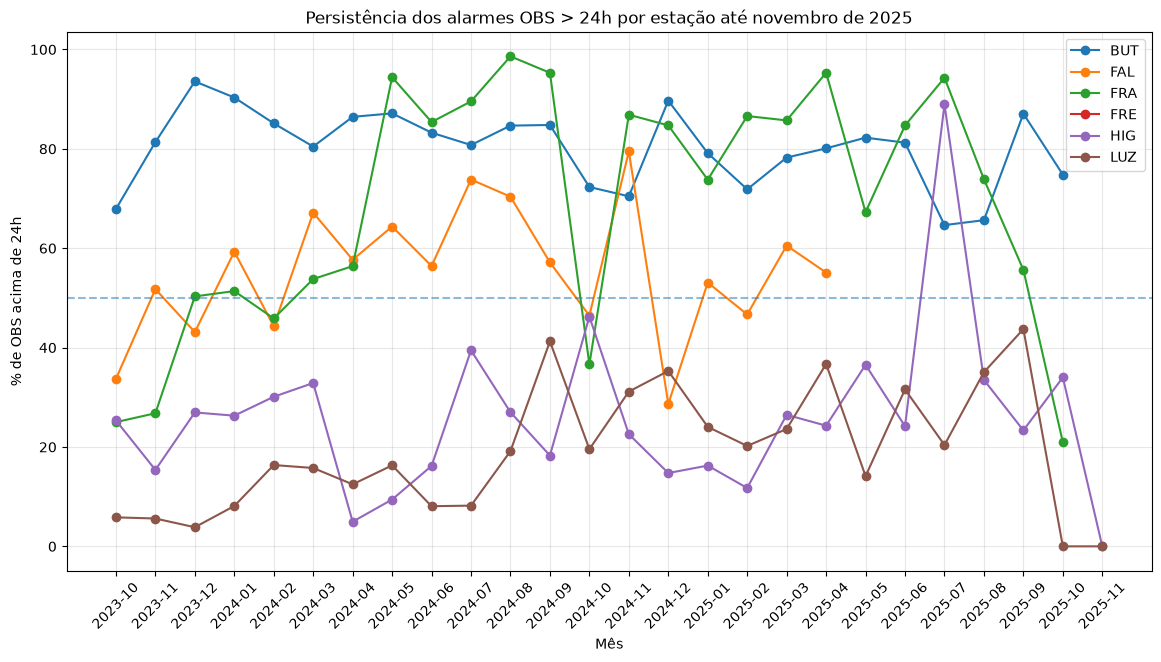

In [135]:
# Garantir que o mês esteja em formato de período
obs_mes_estacao["mes_periodo"] = pd.PeriodIndex(
    obs_mes_estacao["mes"],
    freq="M"
)

# Filtrar até novembro de 2025
obs_mes_estacao_plot = obs_mes_estacao[
    obs_mes_estacao["mes_periodo"] <= pd.Period("2025-11", freq="M")
].copy()

plt.figure(figsize=(14, 7))

for estacao in obs_mes_estacao_plot["estacao"].unique():

    dados = obs_mes_estacao_plot[
        (obs_mes_estacao_plot["estacao"] == estacao)
        & (obs_mes_estacao_plot["eventos"] >= 30)
    ].sort_values("mes_periodo")

    plt.plot(
        dados["mes"],
        dados["pct_acima_24h"],
        marker="o",
        label=estacao
    )

plt.axhline(
    50,
    linestyle="--",
    alpha=0.5
)

plt.ylabel("% de OBS acima de 24h")
plt.xlabel("Mês")
plt.title(
    "Persistência dos alarmes OBS > 24h por estação até novembro de 2025"
)

plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [137]:
# Converter mês para período
obs_mes_estacao["mes_periodo"] = pd.PeriodIndex(
    obs_mes_estacao["mes"],
    freq="M"
)

# Mesmo recorte utilizado na análise anterior
obs_mes_validos = obs_mes_estacao[
    (obs_mes_estacao["eventos"] >= 30)
    & (obs_mes_estacao["mes_periodo"] <= pd.Period("2025-11", freq="M"))
].copy()

# Identificar meses em que houve pelo menos um OBS acima de 24h
obs_mes_validos["teve_acima_24h"] = (
    obs_mes_validos["acima_24h"] > 0
)

# Quantidade de meses por estação
meses_acima_24h = (
    obs_mes_validos
    .groupby("estacao")
    .agg(
        meses_analisados=("mes", "nunique"),
        meses_com_alarme_acima_24h=("teve_acima_24h", "sum")
    )
    .reset_index()
)

meses_acima_24h["pct_meses_com_acima_24h"] = (
    meses_acima_24h["meses_com_alarme_acima_24h"]
    / meses_acima_24h["meses_analisados"]
    * 100
)

meses_acima_24h = meses_acima_24h.sort_values(
    "meses_com_alarme_acima_24h",
    ascending=False
)

print(meses_acima_24h.to_string(index=False))

estacao  meses_analisados  meses_com_alarme_acima_24h  pct_meses_com_acima_24h
    BUT                25                          25               100.000000
    FRA                25                          25               100.000000
    HIG                26                          25                96.153846
    LUZ                26                          24                92.307692
    FAL                19                          19               100.000000


In [141]:
# Converter mês para período
obs_mes_estacao["mes_periodo"] = pd.PeriodIndex(
    obs_mes_estacao["mes"],
    freq="M"
)

# Manter o mesmo recorte da análise anterior
obs_mes_plot = obs_mes_estacao[
    (obs_mes_estacao["eventos"] >= 30)
    & (
        obs_mes_estacao["mes_periodo"]
        <= pd.Period("2025-11", freq="M")
    )
].copy()

# Ordenar cronologicamente
obs_mes_plot = obs_mes_plot.sort_values(
    ["mes_periodo", "estacao"]
)

print(
    obs_mes_plot[
        [
            "estacao",
            "mes",
            "eventos",
            "acima_24h"
        ]
    ].to_string(index=False)
)

tabela_mensal_24h = (
    obs_mes_plot
    .pivot(
        index="mes",
        columns="estacao",
        values="acima_24h"
    )
    .fillna(0)
)

print(tabela_mensal_24h)


estacao     mes  eventos  acima_24h
    BUT 2023-10      218        148
    FAL 2023-10      184         62
    FRA 2023-10       44         11
    HIG 2023-10      288         73
    LUZ 2023-10      257         15
    BUT 2023-11      295        240
    FAL 2023-11      396        205
    FRA 2023-11       56         15
    HIG 2023-11      546         84
    LUZ 2023-11      607         34
    BUT 2023-12      980        917
    FAL 2023-12      378        163
    FRA 2023-12      165         83
    HIG 2023-12      449        121
    LUZ 2023-12      572         22
    BUT 2024-01     1324       1196
    FAL 2024-01      172        102
    FRA 2024-01      146         75
    HIG 2024-01      327         86
    LUZ 2024-01      505         41
    BUT 2024-02     1123        956
    FAL 2024-02      237        105
    FRA 2024-02      133         61
    HIG 2024-02      651        196
    LUZ 2024-02      654        107
    BUT 2024-03     1443       1161
    FAL 2024-03      545    

<Figure size 1600x700 with 0 Axes>

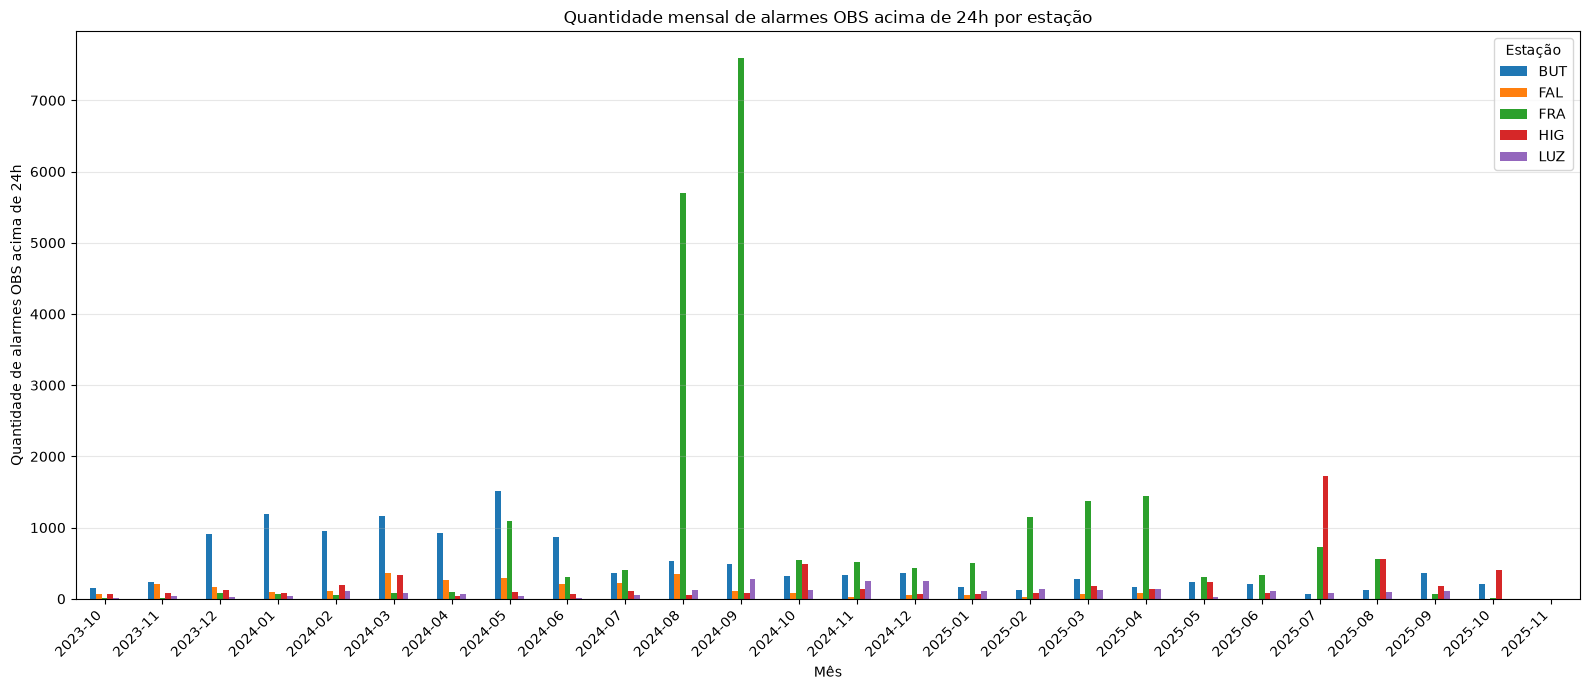

In [142]:
plt.figure(figsize=(16, 7))

tabela_mensal_24h.plot(
    kind="bar",
    figsize=(16, 7)
)

plt.xlabel("Mês")
plt.ylabel("Quantidade de alarmes OBS acima de 24h")

plt.title(
    "Quantidade mensal de alarmes OBS acima de 24h por estação"
)

plt.xticks(
    rotation=45,
    ha="right"
)

plt.legend(
    title="Estação"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.show()

# Passo 14. Conclusão geral das hipóteses

Ao longo do notebook, as hipóteses foram sendo construídas a partir dos padrões observados nos próprios dados.

A análise não partiu de uma resposta previamente definida. Cada hipótese surgiu como uma tentativa de explicar comportamentos identificados durante a exploração das bases e foi mantida ou descartada conforme os testes indicavam a existência, ou não, de evidência suficiente.

## Hipótese 1. Existe um tempo de normalização capaz de separar obstrução de falha?

A primeira hipótese surgiu da ideia de que uma **obstrução transitória** deveria, em princípio, normalizar rapidamente, enquanto uma **falha real de equipamento** poderia permanecer ativa por mais tempo e resultar em uma manutenção registrada no SAP.

Como o código `OBS` foi confirmado como correspondente a obstrução, foi possível construir grupos exploratórios de obstrução e falha utilizando também a associação dos alarmes com avarias registradas no SAP.

A partir dessa classificação, foram testados diferentes limites de tempo de normalização para verificar se existia um ponto capaz de separar os dois tipos de evento.

## Melhor limite encontrado

O melhor resultado foi obtido com um limite de aproximadamente:

> **20 segundos**

Nesse ponto, foram obtidas as seguintes métricas:

- **Sensibilidade:** 96,8%;
- **Especificidade:** 36,1%;
- **Precisão:** 2,5%;
- **Balanced Accuracy:** 0,664;
- **AUC ROC:** 0,669;
- **Average Precision:** 0,023.

## Interpretação dos resultados

A sensibilidade de **96,8%** indicou que o limite era capaz de identificar praticamente todas as falhas existentes na classificação utilizada.

Entretanto, a especificidade de apenas **36,1%** mostrou que uma grande quantidade de obstruções também era classificada incorretamente como falha.

O principal problema apareceu na precisão:

> **Apenas 2,5% dos eventos classificados como falha pela regra correspondiam efetivamente à classe de falha.**

Esse comportamento é especialmente importante porque a base apresentava um forte desbalanceamento entre as classes, com uma quantidade muito maior de obstruções do que de falhas.

Assim, mesmo uma regra com alta sensibilidade produzia um grande número de falsos positivos.

## Avaliação independente do ponto de corte

A curva ROC apresentou:

> **AUC = 0,669**

Esse resultado mostrou que o tempo de normalização possuía algum poder de discriminação entre as classes, mas ainda existia uma grande sobreposição entre os tempos observados para falhas e obstruções.

Como a classe de falha era rara, também foi utilizada a curva Precision-Recall.

O resultado foi:

> **Average Precision = 0,023**

Além disso, nenhum dos limites temporais testados conseguiu atingir uma precisão de **50%**.

Isso significa que não foi encontrado nenhum ponto em que pelo menos metade dos eventos classificados como falha pela regra fosse realmente uma falha.

## Resultado da Hipótese 1

Diante desses resultados, a hipótese foi considerada:

> **Inválida na forma proposta**

Os dados mostraram que o tempo de normalização apresenta algum sinal relacionado à ocorrência de falhas, mas **não possui poder discriminativo suficiente para funcionar isoladamente como critério de classificação**.

Portanto, não foi possível estabelecer uma regra operacional simples do tipo:

> **"Acima de X segundos é falha."**

## Conclusão da Hipótese 1

O tempo de normalização pode ser considerado uma variável potencialmente relevante para análises futuras, especialmente quando combinado com outras informações.

Entretanto, isoladamente, ele não é suficiente para distinguir de forma confiável uma **obstrução transitória** de uma **falha associada à manutenção**.

A primeira hipótese, portanto, não foi sustentada como regra operacional de classificação.

### Hipótese 2. Determinados defeitos possuem um tempo característico de normalização?

Depois que a primeira hipótese não se sustentou, surgiu uma segunda possibilidade.

Mesmo que não existisse um limite universal capaz de separar falhas e obstruções, talvez **alguns defeitos específicos apresentassem tempos de normalização característicos**.

## Origem da hipótese

Essa hipótese surgiu porque, ao agrupar os alarmes pela variável `Defeito`, alguns casos apresentaram medianas e intervalos interquartis aparentemente muito concentrados.

Entre os principais exemplos observados inicialmente estavam:

- `CORREIA DE TRAÇÃO DANIFICADA`;
- `PED CAN BOX SEM COMUNICAÇÃO`;
- `OBSTRUÇÃO DE FECHAMENTO`.

Em um primeiro momento, esses resultados pareciam indicar que determinados defeitos possuíam uma espécie de:

> **assinatura temporal**

Ou seja, certos defeitos pareciam estar associados a tempos de normalização relativamente específicos e pouco dispersos.

## Identificação da pseudorrepetição

Antes de aceitar essa conclusão, foi realizada uma validação adicional para verificar quantos eventos de manutenção independentes existiam por trás de cada grupo de alarmes.

Essa análise revelou um problema importante de **pseudorrepetição**.

Por exemplo:

- os **44 registros** associados a `CORREIA DE TRAÇÃO DANIFICADA` correspondiam a apenas **2 manutenções independentes**;
- os **37 registros** de `PED CAN BOX SEM COMUNICAÇÃO` correspondiam a apenas **1 manutenção independente**.

Isso significava que vários alarmes estavam repetindo o comportamento temporal de uma mesma ocorrência de manutenção.

Dessa forma, a concentração observada nos tempos não representava necessariamente diversos eventos independentes com comportamento semelhante.

Em alguns casos, ela refletia apenas a repetição de vários alarmes vinculados à mesma avaria.

## Correção da unidade de análise

Para corrigir esse problema, a unidade de análise foi alterada.

Em vez de considerar:

> **1 alarme = 1 observação**

passou-se a considerar:

> **1 manutenção = 1 observação**

Os alarmes associados a uma mesma manutenção foram agregados, impedindo que uma única ocorrência com muitos alarmes tivesse peso excessivo sobre os resultados.

## Resultados após a correção

Depois da remoção da pseudorrepetição, os padrões temporais que anteriormente pareciam muito concentrados praticamente desapareceram.

Mesmo o melhor caso identificado, `TROLLEY DESAJUSTADO`, apresentou:

- dispersão relevante entre os eventos;
- diferentes faixas de tempo de normalização;
- ausência de concentração em torno de um único valor.

A análise mais detalhada desse defeito mostrou inclusive a presença de diferentes regimes temporais, com eventos praticamente instantâneos, eventos de alguns minutos e outros com duração muito superior.

Isso indicou que mesmo o caso aparentemente mais promissor não possuía uma assinatura temporal única e estável.

## Resultado da Hipótese 2

Diante desses resultados, a segunda hipótese foi considerada:

> **Não sustentada pelos dados**

Não foi encontrada evidência robusta de que um determinado defeito possuísse um único tempo de normalização suficientemente estável para caracterizá-lo.

## Conclusão da Hipótese 2

Os dados indicam que determinados defeitos podem apresentar **tendências ou distribuições temporais particulares**, mas não foi encontrada evidência suficiente para estabelecer um tempo único e característico de normalização.

Além disso, a análise mostrou a importância de considerar corretamente a independência das observações.

A pseudorrepetição produzia padrões aparentemente fortes que desapareceram quando cada manutenção passou a ser tratada como uma única unidade de análise.

Assim, o tempo de normalização, isoladamente, também não se mostrou suficiente para identificar de forma confiável o tipo de defeito associado a um evento.

### Hipótese 3. A persistência dos alarmes depende da estação?

Durante a investigação de `TROLLEY DESAJUSTADO`, foi observado que **21 dos 22 eventos analisados pertenciam à estação HIG**.

Esse resultado levantou uma nova possibilidade: talvez o comportamento temporal estivesse relacionado não apenas ao defeito, mas também à **estação em que o evento ocorria**.

## Origem da hipótese

A partir dessa observação, a análise passou a investigar se a persistência dos alarmes variava sistematicamente entre as diferentes estações.

Para isso, foi comparada a proporção de alarmes cuja duração ultrapassava:

> **24 horas**

Inicialmente, foram considerados todos os Alarmes PSD com duração calculável.

Os resultados mostraram diferenças expressivas entre as estações:

* **FRA:** aproximadamente **85,8%** dos alarmes acima de 24 horas;
* **BUT:** aproximadamente **75,5%**;
* **FAL:** aproximadamente **47,1%**;
* **HIG:** aproximadamente **29,7%**;
* **LUZ:** aproximadamente **17,9%**;
* **FRE:** **0%**.

Esses valores indicaram que a persistência dos alarmes não estava distribuída de maneira uniforme entre os locais.

## Primeira validação estatística

Para verificar se as diferenças entre as estações poderiam ser atribuídas apenas ao acaso, foi aplicado um **teste qui-quadrado de independência**.

O resultado indicou uma associação estatisticamente significativa entre:

* a estação;
* a permanência do alarme acima de 24 horas.

Entretanto, essa primeira análise ainda possuía uma possível fonte de confusão.

As estações poderiam apresentar diferentes composições de códigos de alarme. Dessa forma, a diferença observada poderia estar associada ao **tipo de evento registrado em cada local**, e não necessariamente à estação.

Por esse motivo, foi necessário controlar o tipo de alarme.

---

## Validação da hipótese utilizando apenas o alarme `OBS`

Para eliminar o possível efeito da composição dos tipos de alarme, a análise foi repetida utilizando exclusivamente registros:

> `Alarme == "OBS"`

Essa abordagem permitiu comparar **o mesmo tipo de evento em diferentes estações**.

Mesmo após manter constante o código de alarme, as diferenças permaneceram muito expressivas:

* **FRA:** **85,76%** dos `OBS` acima de 24 horas;
* **BUT:** **80,07%**;
* **FAL:** **47,14%**;
* **HIG:** **29,67%**;
* **LUZ:** **17,87%**;
* **FRE:** **0%**.

Isso mostrou que a diferença observada anteriormente não podia ser explicada apenas pela presença de tipos distintos de alarme em cada estação.

## Teste qui-quadrado com controle pelo tipo de alarme

O teste qui-quadrado foi então aplicado novamente, considerando apenas os registros `OBS`.

Os resultados foram:

* **Qui-quadrado:** `χ² = 28.276,944`;
* **p-valor:** `p < 0,001`.

O resultado confirmou uma associação estatisticamente significativa entre a estação e a probabilidade de um alarme `OBS` permanecer ativo por mais de 24 horas.

## Risco relativo

Também foi calculado o risco relativo de um alarme `OBS` permanecer ativo por mais de 24 horas em cada estação, comparando cada local com o conjunto das demais estações.

Os principais resultados foram:

* **FRA:** risco relativo de **2,03**;
* **BUT:** risco relativo de **1,56**.

Para FRA, isso significa que um alarme `OBS` apresentou aproximadamente:

> **2 vezes a probabilidade de permanecer ativo por mais de 24 horas**

quando comparado aos alarmes `OBS` registrados no conjunto das demais estações.

Em BUT, essa probabilidade foi aproximadamente:

> **1,56 vez maior**

## Resultado da Hipótese 3

Diante dos resultados encontrados, a terceira hipótese foi considerada:

> **Sustentada pelos dados**

Mesmo após controlar o tipo de alarme, a estação continuou apresentando uma relação forte e estatisticamente significativa com a persistência dos eventos.

Assim, os dados indicam que:

> **A persistência dos alarmes `OBS` depende da estação em que o evento ocorre.**

---

# Conclusão final

As três hipóteses investigadas ao longo do notebook representam uma evolução progressiva da análise.

As duas primeiras procuravam encontrar uma explicação baseada principalmente no **tempo de normalização em si**.

A terceira surgiu justamente a partir das limitações encontradas nas hipóteses anteriores e deslocou a investigação para o **contexto em que os eventos ocorriam**.

## Síntese da Hipótese 1

A primeira hipótese buscou verificar se existia um limite universal de tempo capaz de separar:

> **obstrução transitória** de **falha associada à manutenção**

O melhor limite encontrado foi de aproximadamente **20 segundos**, com alta sensibilidade, mas baixa especificidade e precisão de apenas **2,5%**.

Além disso, nenhum limite temporal atingiu precisão de 50%.

Portanto:

> **O tempo de normalização isoladamente não permite separar de forma confiável uma obstrução de uma falha.**

Não foi possível construir uma regra operacional simples do tipo:

> **"Acima de X segundos é falha."**

## Síntese da Hipótese 2

A segunda hipótese investigou se determinados defeitos possuíam **tempos característicos de normalização**.

Inicialmente, alguns grupos apresentaram distribuições extremamente concentradas, sugerindo possíveis assinaturas temporais.

Entretanto, foi identificado um problema de **pseudorrepetição**: vários alarmes estavam associados à mesma ocorrência de manutenção.

Quando a unidade de análise foi corrigida de:

> **1 alarme = 1 observação**

para:

> **1 manutenção = 1 observação**

os padrões mais fortes praticamente desapareceram.

Mesmo `TROLLEY DESAJUSTADO`, o caso com menor dispersão relativa após a correção, apresentou diferentes regimes de duração.

Portanto:

> **Não foi encontrada evidência robusta de um tempo único e estável de normalização capaz de caracterizar um determinado defeito.**

## Síntese da Hipótese 3

A terceira hipótese surgiu durante a investigação de `TROLLEY DESAJUSTADO`, quando foi percebido que **21 dos 22 eventos pertenciam à estação HIG**.

A partir dessa observação, a análise passou a investigar **onde os eventos ocorriam**, e não apenas quanto tempo demoravam para normalizar.

Foi nesse ponto que apareceu o padrão mais consistente de todo o notebook.

Mesmo mantendo constante o tipo de alarme e analisando exclusivamente eventos `OBS`, a estação continuou apresentando forte relação com a persistência acima de 24 horas.

Os resultados mostraram:

* diferenças expressivas nas proporções entre estações;
* `p < 0,001` no teste qui-quadrado;
* **V de Cramér = 0,586**;
* risco relativo de **2,03** para FRA;
* risco relativo de **1,56** para BUT.

Portanto:

> **A terceira hipótese foi sustentada pelos dados.**

## Principal resultado da análise

O principal resultado encontrado ao longo do notebook foi:

> **A persistência dos alarmes `OBS` não ocorre de maneira uniforme entre as estações. FRA e BUT apresentam comportamento significativamente mais persistente, com maior probabilidade de os alarmes permanecerem sem normalização por mais de 24 horas.**

Esse resultado representa uma mudança importante na interpretação dos dados.

O comportamento temporal parece depender menos de um **limite universal de duração** ou de uma **assinatura específica do defeito** e mais do **contexto local em que o evento ocorre**.

## Limitação da interpretação

É importante destacar que esse resultado **não significa necessariamente que FRA ou BUT demorem mais para reparar fisicamente uma falha**.

A variável analisada nos Alarmes PSD representa:

> **o tempo entre a ocorrência do alarme e sua normalização no sistema**

Esse intervalo pode ou não coincidir com o tempo necessário para realizar um reparo físico.

Portanto, a associação encontrada indica a existência de algum **fator local relacionado à estação**, mas os dados analisados não permitem determinar diretamente qual mecanismo produz essa diferença.

Entre as possíveis explicações estão:

* procedimentos operacionais distintos;
* diferenças nos processos de normalização;
* lógica de reset dos equipamentos;
* configurações específicas do sistema;
* comunicação entre equipamentos e supervisório;
* características locais da infraestrutura;
* diferenças no processo de registro ou encerramento dos eventos;
* persistência física do problema.

## Conclusão geral

O percurso das três hipóteses mostrou que o principal valor da análise não esteve apenas em confirmar uma ideia inicial, mas em **eliminar explicações aparentemente plausíveis até identificar um padrão mais consistente**.

A investigação começou perguntando:

> **"Quanto tempo é suficiente para indicar uma falha?"**

Depois evoluiu para:

> **"Cada defeito possui seu próprio tempo característico?"**

E finalmente chegou a uma questão diferente:

> **"O local onde o alarme ocorre influencia sua persistência?"**

Foi nessa terceira direção que os dados apresentaram a evidência mais forte.

Assim, os resultados sugerem que futuras investigações devem priorizar a compreensão das diferenças operacionais e técnicas entre as estações, especialmente **FRA e BUT**, buscando identificar quais fatores locais podem explicar a elevada persistência dos alarmes `OBS`.
